# IBM AML (AMLSim) — Exploratory Data Analysis

**Dataset:** `LI-Small_accounts.csv` (node metadata) + `LI-Small_transactions.csv` (directed edge list)

Money laundering is a *relational* problem, so this notebook treats the data as a graph from the start:
accounts are nodes, transactions are directed edges. The EDA is organised to answer the questions that
actually drive downstream modelling decisions:

| Section | Question it answers |
|---|---|
| 1–2 | What is actually in these files, and do they join cleanly? |
| 3 | Is the data trustworthy (nulls, dupes, orphan accounts)? |
| 4 | How severe is the class imbalance? |
| 5–6 | What do amounts, currencies and payment rails look like? |
| 7 | Is there temporal structure or burstiness? |
| 8–9 | What does the transaction network look like (degree, hubs, cycles)? |
| 10 | Is there evidence of structuring/smurfing near reporting thresholds? |
| 11 | How do laundering accounts differ from clean ones? |
| 12 | What features and modelling choices does the data justify? |

> **Note on column names.** The public IBM AML files ship with two columns literally both named
> `Account` (sender and receiver). Pandas silently renames the second to `Account.1`. This notebook
> normalises that and several other naming variants up front — do not skip Section 1.

## 0. Configuration

In [10]:
from pathlib import Path

# --- EDIT THESE ---------------------------------------------------------
DATA_DIR = Path("./data")                       # folder holding the CSVs
TX_FILE       = DATA_DIR / "LI-Small_Trans.csv"
ACCOUNTS_FILE = DATA_DIR / "LI-Small_accounts.csv"

# LI-Small has ~7M transaction rows. Set to an int (e.g. 2_000_000) to sample
# while developing, then set to None for the full pass.
NROWS = None

GRAPH_SAMPLE_EDGES = 500_000   # cap for the NetworkX section (memory guard)
RANDOM_SEED        = 42
OUT_DIR            = Path("./eda_output")
# ------------------------------------------------------------------------

OUT_DIR.mkdir(exist_ok=True, parents=True)
print("Transactions:", TX_FILE, "| exists:", TX_FILE.exists())
print("Accounts:    ", ACCOUNTS_FILE, "| exists:", ACCOUNTS_FILE.exists())

Transactions: data/LI-Small_Trans.csv | exists: True
Accounts:     data/LI-Small_accounts.csv | exists: True


In [11]:
import warnings, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings("ignore")
np.random.seed(RANDOM_SEED)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

plt.rcParams.update({
    "figure.figsize": (11, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

def thousands(ax, axis="y"):
    fmt = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)
    return ax

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.3.3 | numpy 2.3.3


## 1. Load & normalise schema

The loader below is deliberately defensive. It maps whatever header variant is present onto a canonical
schema so every downstream cell can rely on fixed names.

In [12]:
CANONICAL_TX = {
    "timestamp":       ["Timestamp", "timestamp", "Date"],
    "from_bank":       ["From Bank", "from_bank", "Sender Bank"],
    "to_bank":         ["To Bank", "to_bank", "Receiver Bank"],
    "from_account":    ["Account", "From Account", "from_account", "Sender Account", "nameOrig"],
    "to_account":      ["Account.1", "To Account", "to_account", "Receiver Account", "nameDest"],
    "amount_received": ["Amount Received", "amount_received"],
    "currency_received":["Receiving Currency", "Amount Received Currency"],
    "amount_paid":     ["Amount Paid", "amount_paid", "Amount"],
    "currency_paid":   ["Payment Currency", "Amount Paid Currency"],
    "payment_format":  ["Payment Format", "payment_format", "Payment Type"],
    "is_laundering":   ["Is Laundering", "is_laundering", "isFraud", "Label"],
}

CANONICAL_ACC = {
    "account_id":   ["Account Number", "Account ID", "Account", "account_id", "acct_id"],
    "bank_id":      ["Bank Name", "Bank", "Bank ID", "bank_id"],
    "entity_id":    ["Entity ID", "Customer ID", "customer_id", "entity_id"],
    "account_type": ["Account Type", "account_type", "Type"],
    "country":      ["Country", "country"],
    "flag":         ["Is Laundering", "Is SAR", "is_sar", "Flag"],
}


def normalise(df, mapping, label):
    # Rename recognised columns to canonical names; report what was and wasn't matched.
    rename, taken = {}, set()
    for canon, candidates in mapping.items():
        for c in candidates:
            if c in df.columns and c not in taken:
                rename[c] = canon
                taken.add(c)
                break
    out = df.rename(columns=rename)
    matched  = sorted(rename.values())
    unmapped = [c for c in df.columns if c not in rename]
    print(f"[{label}] mapped {len(matched)} columns -> {matched}")
    if unmapped:
        print(f"[{label}] left as-is: {unmapped}")
    return out

In [13]:
tx_raw = pd.read_csv(TX_FILE, nrows=NROWS, low_memory=False)
print("raw transaction columns:", list(tx_raw.columns))
tx = normalise(tx_raw, CANONICAL_TX, "transactions")
del tx_raw; gc.collect()

tx.head(5)

raw transaction columns: ['Timestamp', 'From Bank', 'Account', 'To Bank', 'Account.1', 'Amount Received', 'Receiving Currency', 'Amount Paid', 'Payment Currency', 'Payment Format', 'Is Laundering']
[transactions] mapped 11 columns -> ['amount_paid', 'amount_received', 'currency_paid', 'currency_received', 'from_account', 'from_bank', 'is_laundering', 'payment_format', 'timestamp', 'to_account', 'to_bank']


,timestamp,from_bank,from_account,to_bank,to_account,amount_received,currency_received,amount_paid,currency_paid,payment_format,is_laundering
0,2022/09/01 00:08,11,8000ECA90,11,8000ECA90,"3,195,403.0000",US Dollar,"3,195,403.0000",US Dollar,Reinvestment,0
1,2022/09/01 00:21,3402,80021DAD0,3402,80021DAD0,"1,858.9600",US Dollar,"1,858.9600",US Dollar,Reinvestment,0
2,2022/09/01 00:00,11,8000ECA90,1120,8006AA910,"592,571.0000",US Dollar,"592,571.0000",US Dollar,Cheque,0
3,2022/09/01 00:16,3814,8006AD080,3814,8006AD080,12.3200,US Dollar,12.3200,US Dollar,Reinvestment,0
4,2022/09/01 00:00,20,8006AD530,20,8006AD530,"2,941.5600",US Dollar,"2,941.5600",US Dollar,Reinvestment,0


In [14]:
print([curr for curr in tx['currency_paid'].unique()])

['US Dollar', 'Euro', 'Bitcoin', 'Yuan', 'Yen', 'UK Pound', 'Brazil Real', 'Australian Dollar', 'Rupee', 'Ruble', 'Canadian Dollar', 'Mexican Peso', 'Swiss Franc', 'Shekel', 'Saudi Riyal']


In [15]:
if ACCOUNTS_FILE.exists():
    acc_raw = pd.read_csv(ACCOUNTS_FILE, low_memory=False)
    print("raw account columns:", list(acc_raw.columns))
    acc = normalise(acc_raw, CANONICAL_ACC, "accounts")
    del acc_raw; gc.collect()
    display(acc.head(5))
else:
    acc = None
    print("!! accounts file not found — node-metadata sections will be skipped.")

raw account columns: ['Bank Name', 'Bank ID', 'Account Number', 'Entity ID', 'Entity Name']
[accounts] mapped 3 columns -> ['account_id', 'bank_id', 'entity_id']
[accounts] left as-is: ['Bank ID', 'Entity Name']


,bank_id,Bank ID,account_id,entity_id,Entity Name
0,China Bank #2820,314693,81B86A280,800D8CCF0,Corporation #41344
1,France Bank #4585,311253,8187FEA80,800B505E0,Corporation #54497
2,China Bank #2242,39996,803961E00,800D03F60,Partnership #36904
3,National Bank of Newport,331440,81B075800,801567C10,Corporation #16224
4,UK Bank #33,135417,80CF87C80,801085E00,Partnership #72930


### 1.1 Type casting

`Timestamp` in this dataset is `YYYY/MM/DD HH:MM`. Account IDs are hex-ish strings and must stay
strings — casting them to numeric silently collides distinct accounts.

In [16]:
tx["timestamp"] = pd.to_datetime(tx["timestamp"], errors="coerce")
bad_ts = tx["timestamp"].isna().sum()
print(f"unparseable timestamps: {bad_ts:,}")

for c in ("from_account", "to_account"):
    tx[c] = tx[c].astype(str).str.strip()

for c in ("amount_paid", "amount_received"):
    if c in tx:
        tx[c] = pd.to_numeric(tx[c], errors="coerce")

if "is_laundering" in tx:
    tx["is_laundering"] = tx["is_laundering"].astype("int8")

for c in ("payment_format", "currency_paid", "currency_received", "from_bank", "to_bank"):
    if c in tx:
        tx[c] = tx[c].astype("category")

if acc is not None:
    acc["account_id"] = acc["account_id"].astype(str).str.strip()
    for c in ("bank_id", "account_type", "country", "entity_id"):
        if c in acc:
            acc[c] = acc[c].astype("category")

tx.dtypes.to_frame("dtype")

unparseable timestamps: 0


,dtype
timestamp,datetime64[ns]
from_bank,category
from_account,object
to_bank,category
to_account,object
amount_received,float64
currency_received,category
amount_paid,float64
currency_paid,category
payment_format,category


## 2. Shape, schema & memory footprint

In [17]:
mem = tx.memory_usage(deep=True).sum() / 1024**3
print(f"transactions : {tx.shape[0]:,} rows x {tx.shape[1]} cols   ({mem:.2f} GB in memory)")
if acc is not None:
    print(f"accounts     : {acc.shape[0]:,} rows x {acc.shape[1]} cols")

profile = pd.DataFrame({
    "dtype":    tx.dtypes.astype(str),
    "n_unique": tx.nunique(dropna=False),
    "n_null":   tx.isna().sum(),
    "pct_null": (tx.isna().mean() * 100).round(3),
    "sample":   [tx[c].dropna().iloc[0] if tx[c].notna().any() else None for c in tx.columns],
})
profile

transactions : 6,924,049 rows x 11 cols   (0.97 GB in memory)
accounts     : 712,688 rows x 5 cols


,dtype,n_unique,n_null,pct_null,sample
timestamp,datetime64[ns],14533,0,0.0000,2022-09-01 00:08:00
from_bank,category,41814,0,0.0000,11
from_account,object,681281,0,0.0000,8000ECA90
to_bank,category,21588,0,0.0000,11
to_account,object,576176,0,0.0000,8000ECA90
amount_received,float64,1194921,0,0.0000,"3,195,403.0000"
currency_received,category,15,0,0.0000,US Dollar
amount_paid,float64,1204309,0,0.0000,"3,195,403.0000"
currency_paid,category,15,0,0.0000,US Dollar
payment_format,category,7,0,0.0000,Reinvestment


## 3. Data quality & referential integrity

The single most important check here: **does every account appearing in the edge list exist in the node
table?** Orphan accounts break graph joins and quietly drop features later.

In [18]:
dupes = tx.duplicated().sum()
print(f"fully duplicated transaction rows: {dupes:,} ({dupes/len(tx)*100:.4f}%)")

self_loops = (tx["from_account"] == tx["to_account"]).sum()
print(f"self-transfers (from == to):      {self_loops:,} ({self_loops/len(tx)*100:.4f}%)")

nonpos = (tx["amount_paid"] <= 0).sum()
print(f"non-positive amount_paid:         {nonpos:,}")

fully duplicated transaction rows: 8 (0.0001%)
self-transfers (from == to):      804,477 (11.6186%)
non-positive amount_paid:         0


In [19]:
tx_accounts = pd.Index(tx["from_account"].unique()).union(pd.Index(tx["to_account"].unique()))
print(f"distinct accounts in transactions: {len(tx_accounts):,}")

if acc is not None:
    acc_ids   = pd.Index(acc["account_id"].unique())
    orphans   = tx_accounts.difference(acc_ids)   # in edges, missing from nodes
    dormant   = acc_ids.difference(tx_accounts)   # in nodes, never transacted
    dup_nodes = acc["account_id"].duplicated().sum()

    print(f"distinct accounts in accounts.csv: {len(acc_ids):,}")
    print(f"duplicate account_id rows:         {dup_nodes:,}")
    print(f"ORPHANS  (txn account w/o metadata): {len(orphans):,} "
          f"({len(orphans)/len(tx_accounts)*100:.2f}% of active accounts)")
    print(f"DORMANT  (metadata, zero txns):      {len(dormant):,} "
          f"({len(dormant)/len(acc_ids)*100:.2f}% of node table)")
    if len(orphans):
        print("example orphans:", list(orphans[:5]))

distinct accounts in transactions: 705,903
distinct accounts in accounts.csv: 712,684
duplicate account_id rows:         4
ORPHANS  (txn account w/o metadata): 0 (0.00% of active accounts)
DORMANT  (metadata, zero txns):      6,781 (0.95% of node table)


> **Interpretation.** A non-zero orphan count means the node table is not a superset of the edge list.
> Decide explicitly: impute a default node profile, or drop those edges. Never let a left-join create
> silent NaNs in `account_type` and then one-hot encode them as a real category.

## 4. Target variable — class imbalance

In [20]:
vc  = tx["is_laundering"].value_counts()
pct = tx["is_laundering"].value_counts(normalize=True) * 100
imbalance = vc.get(0, 0) / max(vc.get(1, 1), 1)

print(vc.to_string())
print()
print(pct.round(4).to_string())
print(f"\nimbalance ratio  : 1 laundering per {imbalance:,.0f} clean transactions")
print(f"positive rate    : {pct.get(1, 0):.4f}%")
print(f"\n-> A model predicting 'never launder' scores {pct.get(0,0):.2f}% accuracy.")
print("-> Evaluate on PR-AUC / recall@k, NOT accuracy or ROC-AUC.")

is_laundering
0    6920484
1       3565

is_laundering
0   99.9485
1    0.0515

imbalance ratio  : 1 laundering per 1,941 clean transactions
positive rate    : 0.0515%

-> A model predicting 'never launder' scores 99.95% accuracy.
-> Evaluate on PR-AUC / recall@k, NOT accuracy or ROC-AUC.


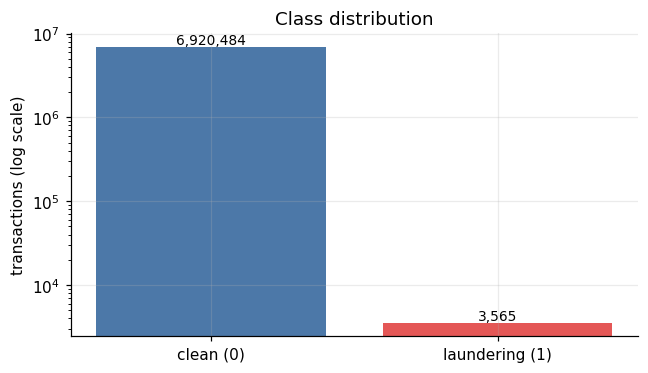

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(["clean (0)", "laundering (1)"], 
              vc.reindex([0, 1]).fillna(0).values,
              color=["#4C78A8", "#E45756"])
ax.set_yscale("log")
ax.set_ylabel("transactions (log scale)")
ax.set_title("Class distribution")
for b, v in zip(bars, vc.reindex([0, 1]).fillna(0).values):
    ax.text(b.get_x() + b.get_width()/2, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

## 5. Transaction amounts

Amounts in AML data are heavy-tailed over several orders of magnitude, so everything is inspected on a
log scale. The `amount_paid` vs `amount_received` gap also encodes FX conversion — a useful signal,
since cross-currency legs are a common layering step.

In [22]:
amt = tx.loc[tx["amount_paid"] > 0, "amount_paid"]
qs  = [0.01, 0.25, 0.5, 0.75, 0.9, 0.99, 0.999, 0.9999]
summary = pd.DataFrame({
    "all":        amt.describe(),
})
print(summary.to_string())
print("\nquantiles:")
print(amt.quantile(qs).to_string())

                         all
count         6,924,049.0000
mean          4,676,035.9727
std       1,544,098,506.6939
min                   0.0000
25%                 175.3800
50%               1,399.4400
75%              12,226.8700
max   3,644,853,662,746.9502

quantiles:
0.0100               0.0100
0.2500             175.3800
0.5000           1,399.4400
0.7500          12,226.8700
0.9000         131,045.1300
0.9900      12,364,829.0200
0.9990     340,682,036.1116
0.9999   4,194,279,393.3300


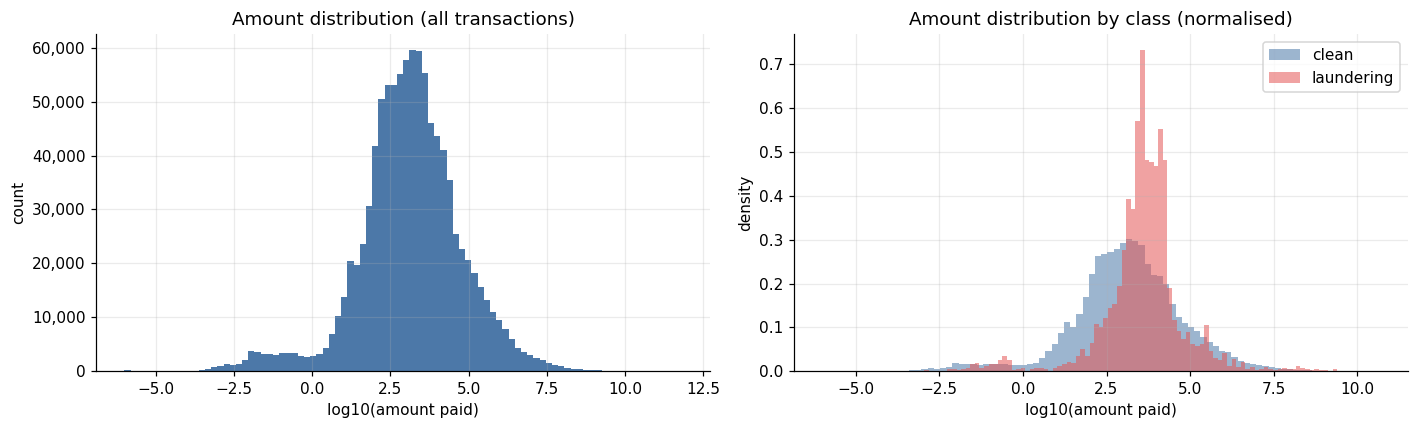

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(np.log10(amt.sample(min(len(amt), 1_000_000), random_state=RANDOM_SEED)),
             bins=90, color="#4C78A8")
axes[0].set_xlabel("log10(amount paid)"); axes[0].set_ylabel("count")
axes[0].set_title("Amount distribution (all transactions)")
thousands(axes[0])

for lab, sub, col in [("clean", tx.loc[(tx.is_laundering == 0) & (tx.amount_paid > 0), "amount_paid"], "#4C78A8"),
                      ("laundering", tx.loc[(tx.is_laundering == 1) & (tx.amount_paid > 0), "amount_paid"], "#E45756")]:
    s = sub.sample(min(len(sub), 300_000), random_state=RANDOM_SEED)
    if len(s):
        axes[1].hist(np.log10(s), bins=90, density=True, alpha=0.55, label=lab, color=col)
axes[1].set_xlabel("log10(amount paid)"); axes[1].set_ylabel("density")
axes[1].set_title("Amount distribution by class (normalised)")
axes[1].legend()
plt.tight_layout(); plt.show()

In [24]:
if {"amount_paid", "amount_received"} <= set(tx.columns):
    fx = tx["amount_paid"].ne(tx["amount_received"])
    print(f"legs where paid != received (FX conversion): {fx.sum():,} ({fx.mean()*100:.2f}%)")
    print("\nlaundering rate by FX-conversion flag:")
    print((tx.groupby(fx)["is_laundering"].agg(["mean", "size"])
             .rename(columns={"mean": "laundering_rate", "size": "n"})
             .assign(laundering_rate=lambda d: (d.laundering_rate*100).round(4))).to_string())

legs where paid != received (FX conversion): 98,858 (1.43%)

laundering rate by FX-conversion flag:
       laundering_rate        n
False           0.0522  6825191
True            0.0000    98858


## 6. Categorical structure — payment rails, currencies, banks

The key view is not raw frequency but **laundering rate per category weighted by volume**. A rail with a
high rate but 12 transactions is noise; a rail with a moderate rate and 400k transactions is a control point.

In [25]:
def rate_by(col, min_n=50, top=20):
    if col not in tx.columns:
        print(f"(skipped: {col} not present)"); return None
    g = (tx.groupby(col, observed=True)["is_laundering"]
           .agg(n="size", n_laundering="sum", rate="mean"))
    g["rate_pct"] = (g["rate"] * 100).round(4)
    g["share_of_volume_pct"] = (g["n"] / len(tx) * 100).round(3)
    g = g[g["n"] >= min_n].drop(columns="rate")
    return g.sort_values("rate_pct", ascending=False).head(top)

pf = rate_by("payment_format")
pf

,n,n_laundering,rate_pct,share_of_volume_pct
payment_format,,,,
ACH,796581,2611,0.3278,11.5050
Bitcoin,309208,110,0.0356,4.4660
Cash,655688,124,0.0189,9.4700
Cheque,2503158,459,0.0183,36.1520
Credit Card,1780389,261,0.0147,25.7130
Reinvestment,650458,0,0.0000,9.3940
Wire,228567,0,0.0000,3.3010


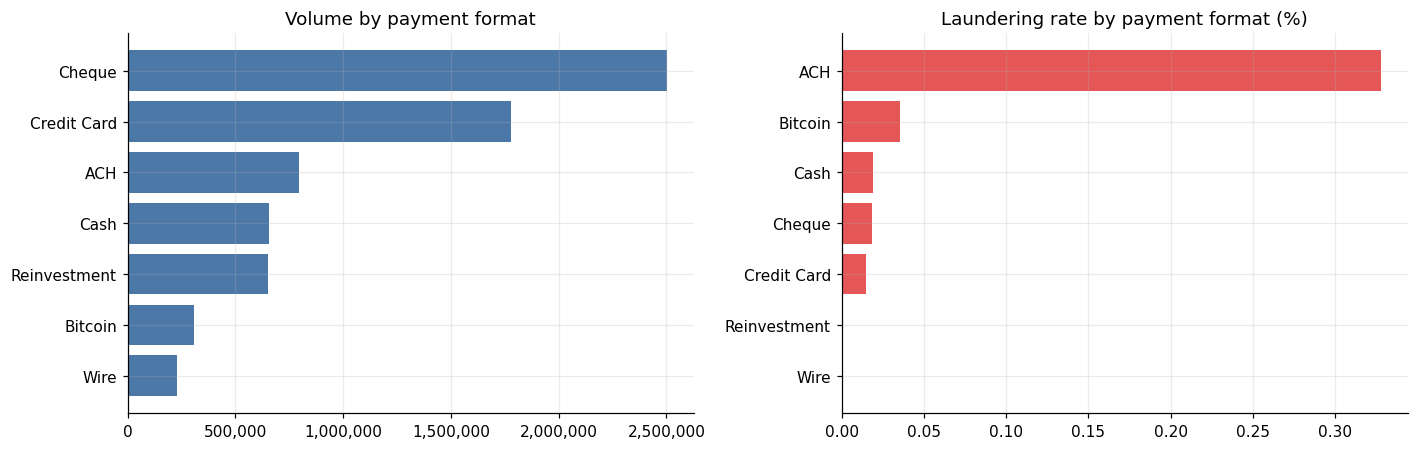

In [26]:
if pf is not None and len(pf):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    order = pf.sort_values("n", ascending=True)
    axes[0].barh(order.index.astype(str), order["n"], color="#4C78A8")
    axes[0].set_title("Volume by payment format"); thousands(axes[0], "x")

    order2 = pf.sort_values("rate_pct", ascending=True)
    axes[1].barh(order2.index.astype(str), order2["rate_pct"], color="#E45756")
    axes[1].set_title("Laundering rate by payment format (%)")
    plt.tight_layout(); plt.show()

In [27]:
print("=== receiving currency ===")
display(rate_by("currency_received", top=15))

print("=== cross-border / cross-bank ===")
if {"from_bank", "to_bank"} <= set(tx.columns):
    tx["cross_bank"] = (tx["from_bank"].astype(str) != tx["to_bank"].astype(str))
    print((tx.groupby("cross_bank")["is_laundering"]
             .agg(n="size", rate="mean")
             .assign(rate_pct=lambda d: (d["rate"]*100).round(4))
             .drop(columns="rate")).to_string())

=== receiving currency ===


,n,n_laundering,rate_pct,share_of_volume_pct
currency_received,,,,
Euro,1596407,1025,0.0642,23.0560
US Dollar,2537242,1456,0.0574,36.6440
Canadian Dollar,177966,86,0.0483,2.5700
Saudi Riyal,261882,115,0.0439,3.7820
Ruble,89140,39,0.0438,1.2870
Mexican Peso,85374,37,0.0433,1.2330
UK Pound,98000,40,0.0408,1.4150
Yen,211631,86,0.0406,3.0560
Swiss Franc,140076,56,0.0400,2.0230


=== cross-border / cross-bank ===
                  n  rate_pct
cross_bank                   
False        912003    0.0080
True        6012046    0.0581


In [28]:
if {"currency_paid", "currency_received"} <= set(tx.columns):
    tx["currency_mismatch"] = (tx["currency_paid"].astype(str) != tx["currency_received"].astype(str))
    print("laundering rate by currency mismatch:")
    print((tx.groupby("currency_mismatch")["is_laundering"]
             .agg(n="size", rate="mean")
             .assign(rate_pct=lambda d: (d["rate"]*100).round(4))
             .drop(columns="rate")).to_string())

laundering rate by currency mismatch:
                         n  rate_pct
currency_mismatch                   
False              6825173    0.0522
True                 98876    0.0000


## 7. Temporal structure

Two things matter: (a) whether laundering is uniformly spread or clustered in campaigns, which dictates
**time-based train/test splitting**, and (b) burstiness at the account level, which is the raw material
for velocity features.

In [29]:
tx["date"]  = tx["timestamp"].dt.floor("D")
tx["hour"]  = tx["timestamp"].dt.hour
tx["dow"]   = tx["timestamp"].dt.dayofweek

print("date range:", tx["timestamp"].min(), "->", tx["timestamp"].max())
print("span      :", (tx["timestamp"].max() - tx["timestamp"].min()))
print("distinct days:", tx["date"].nunique())

date range: 2022-09-01 00:00:00 -> 2022-09-17 15:28:00
span      : 16 days 15:28:00
distinct days: 17


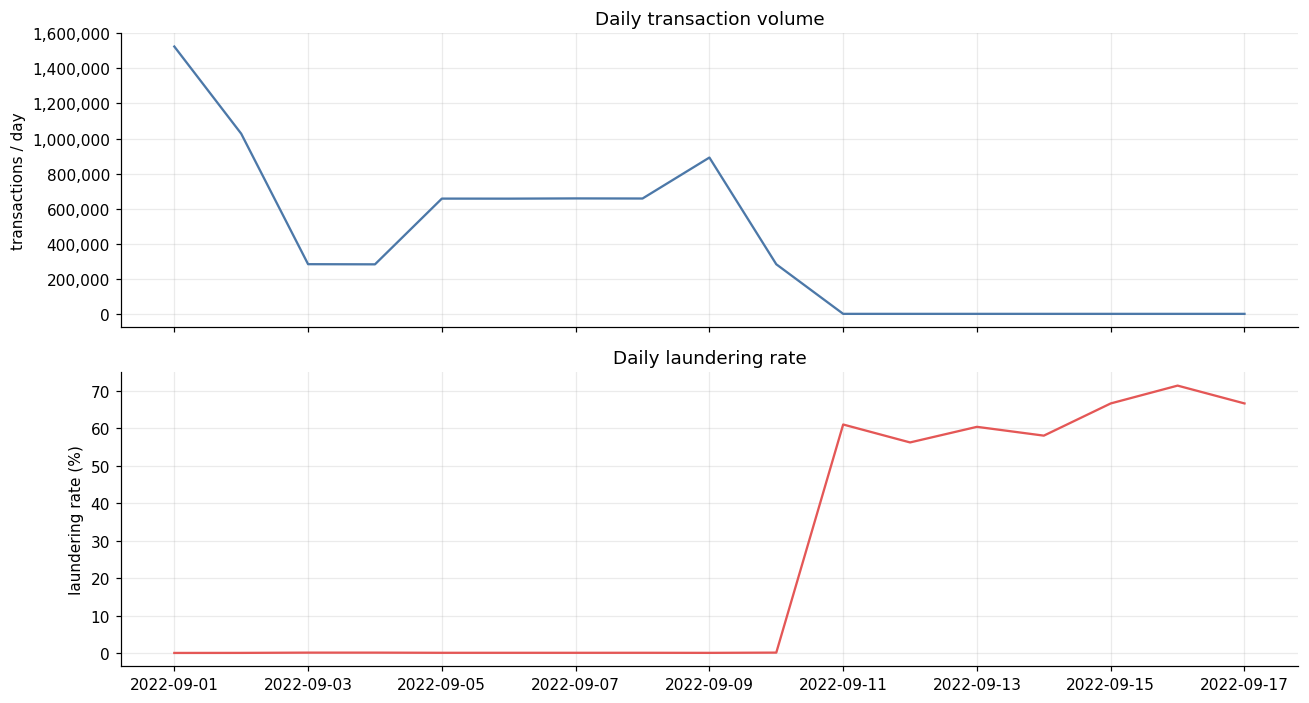

,n,n_laundering,rate_pct
count,17.0000,17.0000,17.0000
mean,"407,297.0000",209.7059,25.9512
std,"455,982.4420",167.4682,32.0678
min,3.0000,2.0000,0.0203
25%,48.0000,27.0000,0.0563
50%,"282,877.0000",292.0000,0.1031
75%,"657,938.0000",367.0000,60.4167
max,"1,524,807.0000",402.0000,71.4286


In [30]:
daily = tx.groupby("date").agg(n=("is_laundering", "size"),
                               n_laundering=("is_laundering", "sum"))
daily["rate_pct"] = daily["n_laundering"] / daily["n"] * 100

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
axes[0].plot(daily.index, daily["n"], color="#4C78A8")
axes[0].set_ylabel("transactions / day"); axes[0].set_title("Daily transaction volume")
thousands(axes[0])
axes[1].plot(daily.index, daily["rate_pct"], color="#E45756")
axes[1].set_ylabel("laundering rate (%)"); axes[1].set_title("Daily laundering rate")
plt.tight_layout(); plt.show()

display(daily.describe())

> If the daily volume plot shows a sharp ramp at the start or a cliff at the end, those are simulator
> warm-up/cool-down artefacts. Trim them before splitting, or the model learns the boundary instead of
> the behaviour.

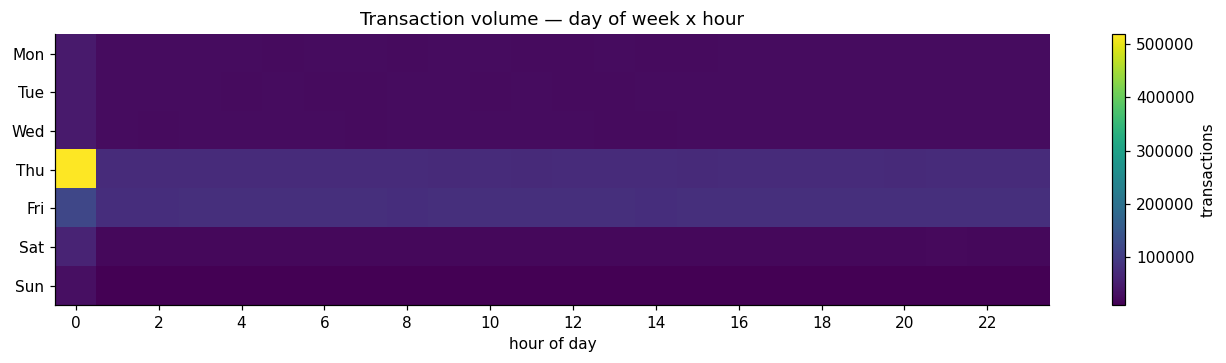

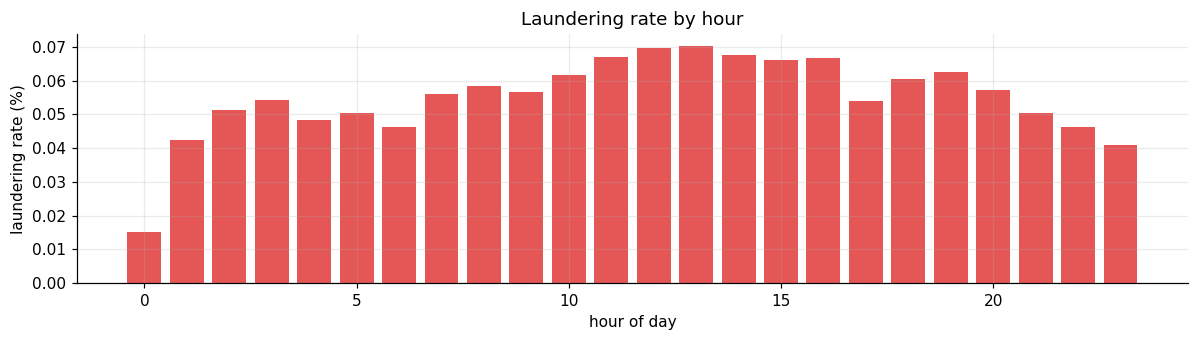

In [31]:
pivot = (tx.pivot_table(index="dow", columns="hour", values="is_laundering",
                        aggfunc="size", observed=True)
           .reindex(range(7)))
fig, ax = plt.subplots(figsize=(12, 3.4))
im = ax.imshow(pivot.values, aspect="auto", cmap="viridis")
ax.set_yticks(range(7), ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"])
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hour of day")
ax.set_title("Transaction volume — day of week x hour")
ax.grid(False); plt.colorbar(im, ax=ax, label="transactions")
plt.tight_layout(); plt.show()

hourly = (tx.groupby("hour")["is_laundering"].mean() * 100)
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(hourly.index, hourly.values, color="#E45756")
ax.set_xlabel("hour of day"); ax.set_ylabel("laundering rate (%)")
ax.set_title("Laundering rate by hour")
plt.tight_layout(); plt.show()

### 7.1 Burstiness

Rapid-fire transfers from a single account are a core structuring signal. Here we measure the median
inter-transaction gap per sending account and compare flagged vs clean accounts.

                median_gap_min  min_gap_min  n_sent
ever_laundered                                     
0                     735.0000     266.0000  2.0000
1                     961.0000       5.0000  3.0000


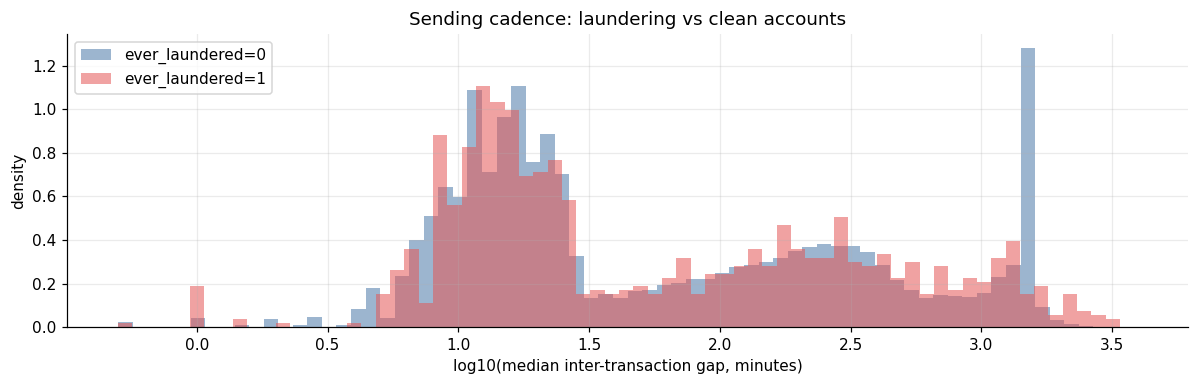

21755

In [32]:
tx_sorted = tx[["from_account", "timestamp", "is_laundering"]].sort_values(["from_account", "timestamp"])
tx_sorted["gap_min"] = (tx_sorted.groupby("from_account", observed=True)["timestamp"]
                                 .diff().dt.total_seconds() / 60)

gap_stats = (tx_sorted.dropna(subset=["gap_min"])
             .groupby("from_account", observed=True)
             .agg(median_gap_min=("gap_min", "median"),
                  min_gap_min=("gap_min", "min"),
                  n_sent=("gap_min", "size"),
                  ever_laundered=("is_laundering", "max")))

print(gap_stats.groupby("ever_laundered")[["median_gap_min", "min_gap_min", "n_sent"]]
      .median().to_string())

burst = gap_stats[gap_stats["n_sent"] >= 5]
fig, ax = plt.subplots(figsize=(11, 3.6))
for lab, col in [(0, "#4C78A8"), (1, "#E45756")]:
    s = burst.loc[burst.ever_laundered == lab, "median_gap_min"]
    s = s[s > 0]
    if len(s):
        ax.hist(np.log10(s), bins=70, density=True, alpha=0.55,
                label=f"ever_laundered={lab}", color=col)
ax.set_xlabel("log10(median inter-transaction gap, minutes)"); ax.set_ylabel("density")
ax.set_title("Sending cadence: laundering vs clean accounts"); ax.legend()
plt.tight_layout(); plt.show()

del tx_sorted; gc.collect()

## 8. Account-level aggregation

Collapse the edge list into a node feature table: degree, volume, net flow, counterparty diversity.
This table is the bridge between transaction-level EDA and the graph section — and is reusable directly
as GNN node features.

In [33]:
out_agg = (tx.groupby("from_account", observed=True)
             .agg(out_degree=("to_account", "size"),
                  out_unique=("to_account", "nunique"),
                  out_amount=("amount_paid", "sum"),
                  out_amount_mean=("amount_paid", "mean"),
                  out_amount_std=("amount_paid", "std"),
                  out_laundering=("is_laundering", "sum"))
             .rename_axis("account_id"))

in_agg = (tx.groupby("to_account", observed=True)
            .agg(in_degree=("from_account", "size"),
                 in_unique=("from_account", "nunique"),
                 in_amount=("amount_received", "sum") if "amount_received" in tx else ("amount_paid", "sum"),
                 in_amount_mean=("amount_paid", "mean"),
                 in_laundering=("is_laundering", "sum"))
            .rename_axis("account_id"))

nodes = out_agg.join(in_agg, how="outer").fillna(0)
nodes["degree"]      = nodes["in_degree"] + nodes["out_degree"]
nodes["net_flow"]    = nodes["in_amount"] - nodes["out_amount"]
nodes["flow_ratio"]  = nodes["out_amount"] / nodes["in_amount"].replace(0, np.nan)
nodes["fan_in"]      = nodes["in_unique"]
nodes["fan_out"]     = nodes["out_unique"]
nodes["fan_ratio"]   = nodes["fan_out"] / nodes["fan_in"].replace(0, np.nan)
nodes["is_laundering_node"] = ((nodes["in_laundering"] + nodes["out_laundering"]) > 0).astype("int8")

print(f"node table: {nodes.shape[0]:,} accounts x {nodes.shape[1]} features")
print(f"accounts touching >=1 laundering txn: {nodes['is_laundering_node'].sum():,} "
      f"({nodes['is_laundering_node'].mean()*100:.3f}%)")
nodes.head()

node table: 705,903 accounts x 18 features
accounts touching >=1 laundering txn: 5,304 (0.751%)


,out_degree,out_unique,out_amount,out_amount_mean,out_amount_std,out_laundering,in_degree,in_unique,in_amount,in_amount_mean,in_laundering,degree,net_flow,flow_ratio,fan_in,fan_out,fan_ratio,is_laundering_node
account_id,,,,,,,,,,,,,,,,,,
10042B660,"222,037.0000","18,942.0000","73,113,736,651.5400","329,286.2750","12,410,256.6152",314.0000,"1,553.0000",785.0000,"803,053.5000",517.0982,0.0000,"223,590.0000","-73,112,933,598.0400","91,044.6647",785.0000,"18,942.0000",24.1299,1
10042B6A8,"138,777.0000","11,877.0000","37,451,441,299.4600","269,867.7828","6,074,104.2692",196.0000,951.0000,478.0000,"414,927.1800",436.3062,0.0000,"139,728.0000","-37,451,026,372.2800","90,260.2748",478.0000,"11,877.0000",24.8473,1
10042B6F0,"42,385.0000","3,611.0000","105,904,323,562.0100","2,498,627.4286","71,323,439.0905",48.0000,345.0000,176.0000,"1,421,533.4500","4,120.3868",0.0000,"42,730.0000","-105,902,902,028.5600","74,500.0574",176.0000,"3,611.0000",20.5170,1
10042B738,"18,213.0000","1,560.0000","924,295,797,491.3800","50,749,233.9258","2,523,946,981.5094",28.0000,135.0000,70.0000,"6,197,232.2900","45,905.4244",0.0000,"18,348.0000","-924,289,600,259.0900","149,146.5471",70.0000,"1,560.0000",22.2857,1
10042B780,"30,802.0000","2,620.0000","729,181,092,474.4399","23,673,173.5756","436,771,939.1907",32.0000,223.0000,118.0000,"6,788,354.4200","30,441.0512",0.0000,"31,025.0000","-729,174,304,120.0199","107,416.4735",118.0000,"2,620.0000",22.2034,1


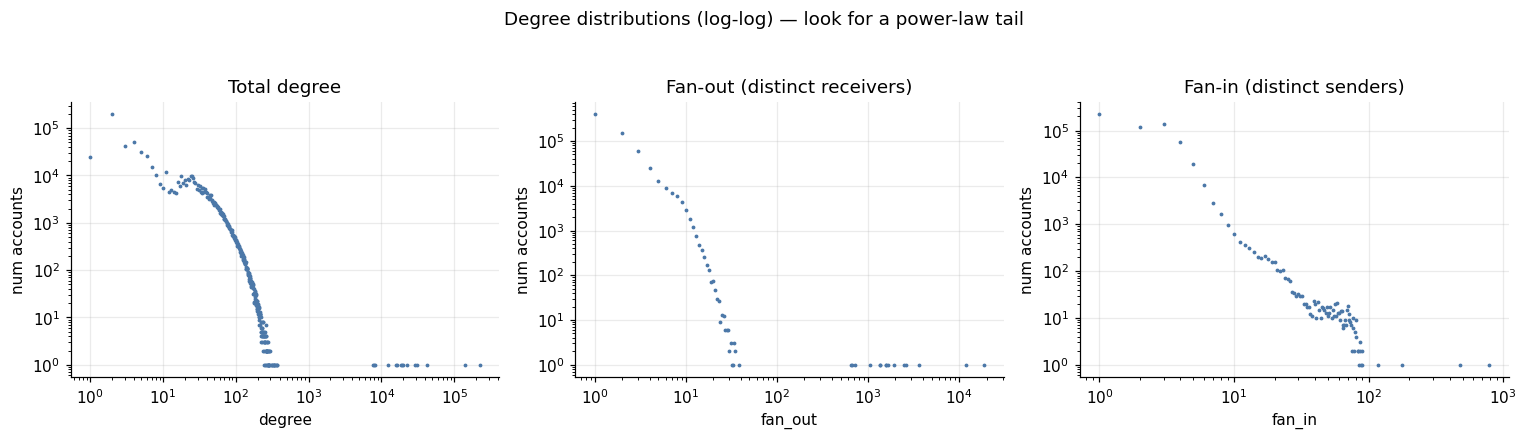

Top 10 fan-out accounts (potential distributors):


,fan_out,fan_in,out_amount,is_laundering_node
account_id,,,,
10042B660,"18,942.0000",785.0000,"73,113,736,651.5400",1
10042B6A8,"11,877.0000",478.0000,"37,451,441,299.4600",1
10042B6F0,"3,611.0000",176.0000,"105,904,323,562.0100",1
10042B780,"2,620.0000",118.0000,"729,181,092,474.4399",1
10042BA51,"2,474.0000",42.0000,"762,910.6619",1
10042BA08,"1,928.0000",86.0000,"23,318,839,990.6300",1
10042B8A0,"1,637.0000",81.0000,"9,356,174,980.5600",1
10042B930,"1,594.0000",67.0000,"28,700,687,549.9500",1
10042B738,"1,560.0000",70.0000,"924,295,797,491.3800",1


Top 10 fan-in accounts (potential collectors / mules):


,fan_in,fan_out,in_amount,is_laundering_node
account_id,,,,
10042B660,785.0000,"18,942.0000","803,053.5000",1
10042B6A8,478.0000,"11,877.0000","414,927.1800",1
10042B6F0,176.0000,"3,611.0000","1,421,533.4500",1
10042B780,118.0000,"2,620.0000","6,788,354.4200",1
808283270,90.0000,2.0000,"9,129,985.8000",0
80AC3D4E0,90.0000,0.0000,"44,314,373.2500",0
818923590,89.0000,2.0000,"871,846.5900",0
80AEBC5F0,88.0000,1.0000,"6,908,260.7000",0
805ADEA90,87.0000,1.0000,"13,367,492.2700",0


In [34]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, title in zip(axes,
                          ["degree", "fan_out", "fan_in"],
                          ["Total degree", "Fan-out (distinct receivers)", "Fan-in (distinct senders)"]):
    s = nodes[col]; s = s[s > 0]
    counts = s.value_counts().sort_index()
    ax.loglog(counts.index, counts.values, ".", markersize=3, color="#4C78A8")
    ax.set_xlabel(col); ax.set_ylabel("num accounts"); ax.set_title(title)
plt.suptitle("Degree distributions (log-log) — look for a power-law tail", y=1.04)
plt.tight_layout(); plt.show()

print("Top 10 fan-out accounts (potential distributors):")
display(nodes.nlargest(10, "fan_out")[["fan_out", "fan_in", "out_amount", "is_laundering_node"]])

print("Top 10 fan-in accounts (potential collectors / mules):")
display(nodes.nlargest(10, "fan_in")[["fan_in", "fan_out", "in_amount", "is_laundering_node"]])

## 9. Network graph analysis

Built with NetworkX on a capped edge sample. For the full LI-Small graph in production, swap to
`graph-tool`, `cuGraph` or PyTorch Geometric — NetworkX will not scale to millions of edges for
PageRank and cycle enumeration.

In [35]:
try:
    import networkx as nx
    HAS_NX = True
except ImportError:
    HAS_NX = False
    print("networkx not installed — run: pip install networkx")

In [36]:
if HAS_NX:
    edges = tx[["from_account", "to_account", "amount_paid", "is_laundering"]]
    if len(edges) > GRAPH_SAMPLE_EDGES:
        # keep ALL laundering edges + random sample of clean ones (preserves signal)
        pos = edges[edges.is_laundering == 1]
        neg = edges[edges.is_laundering == 0].sample(
            max(GRAPH_SAMPLE_EDGES - len(pos), 0), random_state=RANDOM_SEED)
        edges = pd.concat([pos, neg])
        print(f"sampled graph: {len(edges):,} edges ({len(pos):,} laundering kept in full)")

    G = nx.from_pandas_edgelist(edges, "from_account", "to_account",
                                edge_attr=["amount_paid", "is_laundering"],
                                create_using=nx.DiGraph())
    print(f"nodes: {G.number_of_nodes():,}  edges: {G.number_of_edges():,}")
    print(f"density: {nx.density(G):.8f}")

sampled graph: 500,000 edges (3,565 laundering kept in full)
nodes: 322,898  edges: 328,087
density: 0.00000315


In [37]:
if HAS_NX:
    wcc = list(nx.weakly_connected_components(G))
    sizes = pd.Series([len(c) for c in wcc]).sort_values(ascending=False)
    print(f"weakly connected components: {len(wcc):,}")
    print(f"largest component: {sizes.iloc[0]:,} nodes "
          f"({sizes.iloc[0]/G.number_of_nodes()*100:.1f}% of graph)")
    print("\ncomponent size distribution:")
    print(sizes.describe().to_string())
    print("\ntop 10 component sizes:", list(sizes.head(10)))

weakly connected components: 64,168
largest component: 193,911 nodes (60.1% of graph)

component size distribution:
count    64,168.0000
mean          5.0321
std         765.4901
min           1.0000
25%           1.0000
50%           2.0000
75%           2.0000
max     193,911.0000

top 10 component sizes: [193911, 44, 37, 32, 31, 29, 28, 28, 28, 28]


In [38]:
if HAS_NX:
    pr = nx.pagerank(G, alpha=0.85, max_iter=60, tol=1e-6)
    pr_s = pd.Series(pr, name="pagerank")

    lnd_nodes = set(edges.loc[edges.is_laundering == 1, "from_account"]) | \
                set(edges.loc[edges.is_laundering == 1, "to_account"])
    flag = pr_s.index.isin(lnd_nodes)

    print("median PageRank — laundering-linked vs clean:")
    print(f"  laundering-linked: {pr_s[flag].median():.3e}  (n={flag.sum():,})")
    print(f"  clean            : {pr_s[~flag].median():.3e}  (n={(~flag).sum():,})")

    print("\nTop 15 accounts by PageRank:")
    top_pr = pr_s.nlargest(15).to_frame()
    top_pr["laundering_linked"] = top_pr.index.isin(lnd_nodes)
    display(top_pr)

median PageRank — laundering-linked vs clean:
  laundering-linked: 2.647e-06  (n=5,304)
  clean            : 2.657e-06  (n=317,594)

Top 15 accounts by PageRank:


,pagerank,laundering_linked
10042B660,0.0001,True
10042B6A8,0.0001,True
806DFE960,0.0000,False
8144DAE90,0.0000,False
81633C5C0,0.0000,False
80B2D6CC0,0.0000,False
8029E8CF0,0.0000,True
803049310,0.0000,False
814C353A0,0.0000,False
8122A8160,0.0000,False


### 9.1 Cycle detection (layering signature)

Circular flows `A -> B -> C -> A` return funds to origin through intermediaries. Enumerating all cycles
is exponential, so this bounds the search to short cycles on the laundering-linked subgraph.

laundering-linked subgraph: 5,304 nodes, 4,291 edges
cycles found (len<=6, capped at 3000): 589

cycle length distribution:
1    546
2     34
3      3
4      3
5      2
6      1


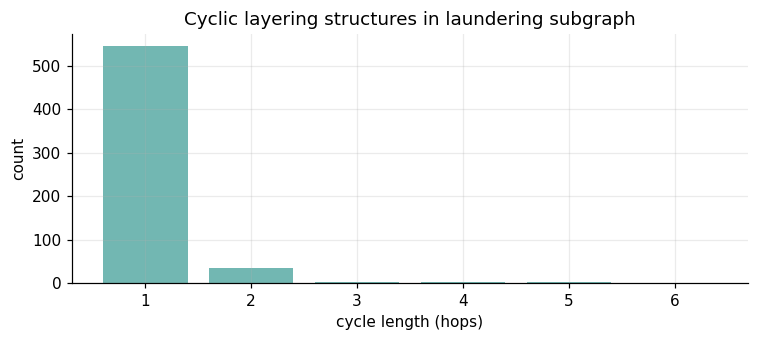


example 3-hop cycles: [['800AF7050', '8016EA8A0', '8018CF810'], ['8003B1FD0', '80267BC80', '8017AD1A0'], ['802BC3160', '8023BE570', '80220D0A0']]


In [39]:
if HAS_NX:
    sub = G.subgraph(lnd_nodes).copy()
    print(f"laundering-linked subgraph: {sub.number_of_nodes():,} nodes, {sub.number_of_edges():,} edges")

    cycles, MAX_CYCLES, MAX_LEN = [], 3000, 6
    try:
        for cyc in nx.simple_cycles(sub, length_bound=MAX_LEN):   # networkx >= 3.1
            cycles.append(cyc)
            if len(cycles) >= MAX_CYCLES:
                break
    except TypeError:
        for cyc in nx.simple_cycles(sub):
            if len(cyc) <= MAX_LEN:
                cycles.append(cyc)
            if len(cycles) >= MAX_CYCLES:
                break

    print(f"cycles found (len<={MAX_LEN}, capped at {MAX_CYCLES}): {len(cycles):,}")
    if cycles:
        lens = pd.Series([len(c) for c in cycles]).value_counts().sort_index()
        print("\ncycle length distribution:")
        print(lens.to_string())
        fig, ax = plt.subplots(figsize=(7, 3.2))
        ax.bar(lens.index.astype(str), lens.values, color="#72B7B2")
        ax.set_xlabel("cycle length (hops)"); ax.set_ylabel("count")
        ax.set_title("Cyclic layering structures in laundering subgraph")
        plt.tight_layout(); plt.show()
        print("\nexample 3-hop cycles:", [c for c in cycles if len(c) == 3][:3])

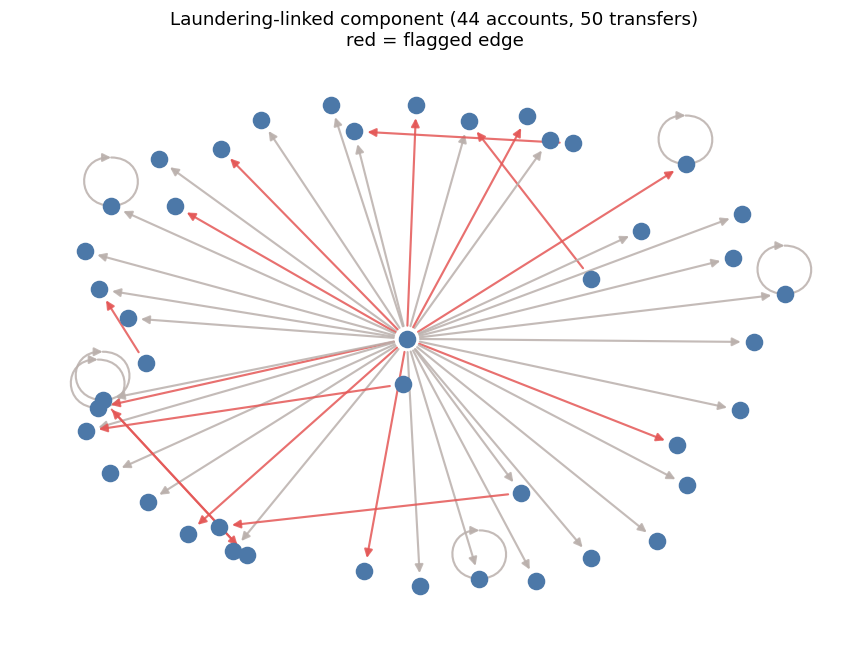

In [40]:
if HAS_NX and len(lnd_nodes) > 2:
    # Visualise one laundering component
    lnd_sub = G.subgraph(lnd_nodes)
    comps = sorted(nx.weakly_connected_components(lnd_sub), key=len, reverse=True)
    target = [c for c in comps if 6 <= len(c) <= 45]
    if target:
        H = lnd_sub.subgraph(target[0])
        pos_layout = nx.spring_layout(H, seed=RANDOM_SEED, k=0.7)
        ecol = ["#E45756" if d["is_laundering"] == 1 else "#BAB0AC" for *_, d in H.edges(data=True)]
        fig, ax = plt.subplots(figsize=(8, 6))
        nx.draw_networkx_nodes(H, pos_layout, node_size=110, node_color="#4C78A8", ax=ax)
        nx.draw_networkx_edges(H, pos_layout, edge_color=ecol, width=1.4,
                               arrowsize=11, alpha=0.85, ax=ax)
        ax.set_title(f"Laundering-linked component ({H.number_of_nodes()} accounts, "
                     f"{H.number_of_edges()} transfers)\nred = flagged edge")
        ax.axis("off"); ax.grid(False)
        plt.tight_layout(); plt.show()
    else:
        print("no laundering component in the 6–45 node range to plot")

### 9.2 Are there other injected ID families besides `10042B`?

The 9 fan-out hubs in the top-10 lists above all share the `10042B` prefix — but that was found by
eyeballing a top-10 table, which only catches families that happen to be the *biggest* fan-out hubs. A
smaller injected family, or one built around fan-in instead of fan-out, would not surface there. A cheap,
exhaustive check: look at the distribution of 6-character `account_id` prefixes. Organic account IDs
should spread roughly evenly across prefixes; a handful of prefixes sitting far above the rest are
simulator-injected scenario families and are all leakage risks for any ID-derived feature (including
hashed ID embeddings).

In [41]:
prefix_len = 6
prefix_counts = pd.Series(tx_accounts).str.slice(0, prefix_len).value_counts()

print(f"distinct {prefix_len}-char account_id prefixes: {len(prefix_counts):,}")
print(f"accounts per prefix -- median: {prefix_counts.median():.0f}, "
      f"99th pct: {prefix_counts.quantile(0.99):.0f}, max: {prefix_counts.max():,}")

# anything more than ~10x the 99th-percentile prefix count is a strong outlier
outlier_cut = max(prefix_counts.quantile(0.99) * 10, 50)
injected_prefixes = prefix_counts[prefix_counts > outlier_cut]

print(f"\nprefixes with count > {outlier_cut:.0f} (candidate injected families):")
display(injected_prefixes.to_frame("n_accounts"))

if len(injected_prefixes) > 1 or (len(injected_prefixes) == 1 and injected_prefixes.index[0] != "10042B"):
    print("\n>> found candidate injected families beyond 10042B -- inspect these before building "
          "any account_id-derived feature (including hashed embeddings).")
else:
    print("\n>> 10042B appears to be the only outlier family at this prefix length. Worth re-checking "
          "at a different prefix length (e.g. 4 or 8 chars) before fully trusting this.")

distinct 6-char account_id prefixes: 106,826
accounts per prefix -- median: 6, 99th pct: 14, max: 22

prefixes with count > 140 (candidate injected families):


,n_accounts



>> 10042B appears to be the only outlier family at this prefix length. Worth re-checking at a different prefix length (e.g. 4 or 8 chars) before fully trusting this.


### 9.3 Cross-currency legs show 0% laundering -- bug or finding?

Section 6 found that of 6,924,049 transactions, **98,876 cross-currency legs carry a 0.0000% laundering
rate**, against 0.0522% for same-currency legs. Not "low" -- *exactly zero*. That is not how a natural
dataset behaves, even a simulated one, so before dropping FX as a feature this needs to be verified
rather than just accepted.

There are two explanations, and they have different consequences:

1. The simulator routes laundering exclusively through single-currency legs -- FX is genuinely
   uninformative and safe to drop.
2. The label is attached to a *pattern* that, by construction, never happens to cross currency at the
   edge level (e.g. layering chains that stay in one currency per hop) -- but the same account could
   still receive in one currency and send out in another as part of a laundering chain, just never on
   the *same* edge. In that case `currency_mismatch` (a per-leg flag) is blind to currency-based
   layering that shows up at the *account* level instead.

The check: for every account touched by a laundering edge, look at whether it receives in one currency
and sends in a different one -- regardless of whether either individual edge is itself flagged.

In [42]:
lnd_edges = tx.loc[tx["is_laundering"] == 1, ["from_account", "to_account",
                                                "currency_paid", "currency_received"]]
lnd_touch_accounts = pd.Index(lnd_edges["from_account"]).union(lnd_edges["to_account"])
print(f"accounts touched by >=1 laundering edge: {len(lnd_touch_accounts):,}")

# currencies used per account, across ALL of that account's transactions (not just flagged ones)
acct_recv_curr = (tx.groupby("to_account", observed=True)["currency_received"]
                    .agg(lambda s: set(s.dropna())))
acct_send_curr = (tx.groupby("from_account", observed=True)["currency_paid"]
                    .agg(lambda s: set(s.dropna())))

acct_curr = pd.DataFrame(index=lnd_touch_accounts)
acct_curr["recv_currencies"] = acct_recv_curr.reindex(lnd_touch_accounts)
acct_curr["send_currencies"] = acct_send_curr.reindex(lnd_touch_accounts)
acct_curr["recv_currencies"] = acct_curr["recv_currencies"].apply(lambda s: s if isinstance(s, set) else set())
acct_curr["send_currencies"] = acct_curr["send_currencies"].apply(lambda s: s if isinstance(s, set) else set())

# an account is "currency-crossing" if the set of currencies it receives in is not a subset of
# (or identical to) the set it sends in -- i.e. money comes in as X and leaves as Y at some point
acct_curr["crosses_currency"] = acct_curr.apply(
    lambda r: len(r["recv_currencies"] - r["send_currencies"]) > 0 and len(r["send_currencies"]) > 0,
    axis=1
)

n_crossing = int(acct_curr["crosses_currency"].sum())
print(f"laundering-linked accounts that receive in one currency and send in another: "
      f"{n_crossing:,} / {len(acct_curr):,} ({n_crossing/len(acct_curr)*100:.2f}%)")

if n_crossing > 0:
    print("\n>> currency-crossing DOES happen at the account level inside laundering chains, even "
          "though no single flagged EDGE crosses currency. `currency_mismatch` as currently defined "
          "(per-leg) is blind to this -- an account-level 'in_currency_set != out_currency_set' "
          "feature is a genuinely different (and non-zero) signal from the one Section 6 tested.")
else:
    print("\n>> confirms explanation (1): laundering truly stays inside single-currency chains "
          "account-by-account, not just edge-by-edge. Safe to drop FX/currency-mismatch features.")

accounts touched by >=1 laundering edge: 6,693
laundering-linked accounts that receive in one currency and send in another: 11 / 6,693 (0.16%)

>> currency-crossing DOES happen at the account level inside laundering chains, even though no single flagged EDGE crosses currency. `currency_mismatch` as currently defined (per-leg) is blind to this -- an account-level 'in_currency_set != out_currency_set' feature is a genuinely different (and non-zero) signal from the one Section 6 tested.


## FX normalisation -- building `amount_usd`

Every dollar-denominated check downstream (structuring thresholds, amount comparisons, `out_amount_std`
sanity checks) is meaningless while 15 currencies are summed as if they were the same unit -- Bitcoin
alone is ~4.5% of rows and its amounts are on a completely different scale. This section builds a single
`amount_usd` column, in two tiers:

1. **Fiat pairs** -- a directed graph of observed pair-rates (median implied rate per currency pair,
   chained through USD where a direct pair is thin or absent).
2. **Bitcoin** -- given its own *daily* rate (not a flat constant), because unlike the fiat pairs it is
   genuinely volatile day to day, not just thinly sampled.

This has to run *before* Section 10 (structuring), Section 10's round-number check, and the
`out_amount_std` de-confounding in Section 11 -- all of them are currently reasoning over
currency-mixed raw amounts.

In [43]:
import networkx as nx

BITCOIN = 'Bitcoin'
MIN_N   = 30   # below this, a direct pair rate isn't trusted; chain or fall back instead

# ============================================================
# STEP 1 — implied rate from every cross-currency leg
# ============================================================
fx = tx.loc[tx['currency_paid'] != tx['currency_received'],
            ['currency_paid', 'currency_received', 'amount_paid', 'amount_received', 'timestamp']].copy()
fx['implied_rate'] = fx['amount_received'] / fx['amount_paid']
fx['date'] = fx['timestamp'].dt.floor('D')

pair_rates = (fx.groupby(['currency_paid', 'currency_received'], observed=True)['implied_rate']
                .agg(median='median', std='std', n='count'))
pair_rates['cv'] = pair_rates['std'] / pair_rates['median']
pair_rates = pair_rates.sort_values('n', ascending=False)
print(f"real pairs observed: {len(pair_rates):,} / 210 possible")

is_btc_pair = (pair_rates.index.get_level_values('currency_paid') == BITCOIN) | \
              (pair_rates.index.get_level_values('currency_received') == BITCOIN)
fiat_pairs = pair_rates[~is_btc_pair]

unstable = fiat_pairs[fiat_pairs['cv'] > 0.05]
if len(unstable):
    print(f"\n{len(unstable)} fiat pairs with cv > 0.05 (noise, usually low n — the two-tier "
          f"fallback below routes around these):")
    print(unstable)

# ============================================================
# STEP 2 — two-tier fiat -> USD graph
#   Tier 1: only pairs with enough observations to trust directly (n >= MIN_N)
#   Tier 2 (fallback): any observed pair at all, used only where Tier 1 has no path
# ============================================================
def build_graph(pairs_df):
    G = nx.DiGraph()
    for (src, dst), row in pairs_df.iterrows():
        G.add_edge(src, dst, rate=row['median'])
        if not G.has_edge(dst, src):
            G.add_edge(dst, src, rate=1 / row['median'])
    return G

def rate_via_graph(G, cur, target='US Dollar'):
    if not (G.has_node(cur) and nx.has_path(G, cur, target)):
        return None
    path = nx.shortest_path(G, cur, target)
    rate = 1.0
    for a, b in zip(path[:-1], path[1:]):
        rate *= G[a][b]['rate']
    return rate

reliable_fiat = fiat_pairs[fiat_pairs['n'] >= MIN_N]
G_reliable = build_graph(reliable_fiat)
G_all      = build_graph(fiat_pairs)   # fallback: every pair, however thin

fiat_currencies = [c for c in tx['currency_paid'].cat.categories if c != BITCOIN]
usd_rate, rate_source = {'US Dollar': 1.0}, {'US Dollar': 'base'}
for cur in fiat_currencies:
    if cur == 'US Dollar':
        continue
    r = rate_via_graph(G_reliable, cur)
    if r is not None:
        usd_rate[cur], rate_source[cur] = r, 'reliable'
        continue
    r = rate_via_graph(G_all, cur)
    if r is not None:
        usd_rate[cur], rate_source[cur] = r, 'fallback(thin)'
    else:
        rate_source[cur] = 'NO PATH — needs an external rate'

rate_report = pd.DataFrame({'usd_rate': pd.Series(usd_rate), 'source': pd.Series(rate_source)})
print("\nfiat -> USD rates:")
print(rate_report)
no_path = [c for c, s in rate_source.items() if 'NO PATH' in s]
if no_path:
    print(f"\n!! no rate found for: {no_path} — supply an external rate for these before proceeding")

# ============================================================
# STEP 3 — Bitcoin gets its OWN per-day rate, pooled across every
# fiat counter-currency (converted to USD first via usd_rate above),
# because it's genuinely volatile, not just thinly sampled
# ============================================================
btc_legs = fx[(fx.currency_paid == BITCOIN) | (fx.currency_received == BITCOIN)].copy()

def implied_btc_usd(row):
    if row['currency_paid'] == BITCOIN and row['currency_received'] in usd_rate:
        return (row['amount_received'] * usd_rate[row['currency_received']]) / row['amount_paid']
    if row['currency_received'] == BITCOIN and row['currency_paid'] in usd_rate:
        return (row['amount_paid'] * usd_rate[row['currency_paid']]) / row['amount_received']
    return np.nan

btc_legs['btc_usd_implied'] = btc_legs.apply(implied_btc_usd, axis=1)
btc_daily = btc_legs.dropna(subset=['btc_usd_implied']).groupby('date')['btc_usd_implied'].median()

all_days = pd.date_range(tx['timestamp'].dt.floor('D').min(), tx['timestamp'].dt.floor('D').max(), freq='D')
btc_daily_rate = btc_daily.reindex(all_days).interpolate(limit_direction='both')
print(f"\nBitcoin daily USD rate ({btc_daily_rate.notna().sum()}/{len(all_days)} days covered):")
print(btc_daily_rate)

# ============================================================
# STEP 4 — apply conversion
#   fiat legs           -> flat usd_rate map
#   any leg touching BTC -> that transaction's own date-specific rate
#   (.astype(float) after .map() is required — currency columns are
#    category dtype, and .map() on a categorical preserves categorical
#    dtype even when the mapped values are numeric)
# ============================================================
tx['date'] = tx['timestamp'].dt.floor('D')
is_btc_paid = tx['currency_paid'] == BITCOIN
is_btc_recv = tx['currency_received'] == BITCOIN

tx['amount_usd'] = np.nan
tx['amount_received_usd'] = np.nan

tx.loc[~is_btc_paid, 'amount_usd'] = (
    tx.loc[~is_btc_paid, 'amount_paid'] *
    tx.loc[~is_btc_paid, 'currency_paid'].map(usd_rate).astype(float)
)
tx.loc[~is_btc_recv, 'amount_received_usd'] = (
    tx.loc[~is_btc_recv, 'amount_received'] *
    tx.loc[~is_btc_recv, 'currency_received'].map(usd_rate).astype(float)
)
tx.loc[is_btc_paid, 'amount_usd'] = (
    tx.loc[is_btc_paid, 'amount_paid'] *
    tx.loc[is_btc_paid, 'date'].map(btc_daily_rate).astype(float)
)
tx.loc[is_btc_recv, 'amount_received_usd'] = (
    tx.loc[is_btc_recv, 'amount_received'] *
    tx.loc[is_btc_recv, 'date'].map(btc_daily_rate).astype(float)
)

unconv = tx['amount_usd'].isna().sum()
print(f"\nunconverted (no rate found): {unconv:,} / {len(tx):,} ({unconv/len(tx)*100:.4f}%)")
if unconv:
    print(tx.loc[tx['amount_usd'].isna(), 'currency_paid'].value_counts())

real pairs observed: 195 / 210 possible

12 fiat pairs with cv > 0.05 (noise, usually low n — the two-tier fallback below routes around these):
                                     median    std    n     cv
currency_paid     currency_received                           
Shekel            US Dollar          0.2961 0.0184  123 0.0621
Canadian Dollar   Saudi Riyal        2.8433 0.2360   61 0.0830
Shekel            Euro               0.2527 0.0382   42 0.1510
Australian Dollar Euro               0.6041 0.0639   39 0.1058
Mexican Peso      Shekel             0.1597 0.0223   22 0.1396
Ruble             Saudi Riyal        0.0482 0.0027   18 0.0554
Swiss Franc       Shekel             3.6907 0.4880   12 0.1322
Rupee             Yen                1.4351 0.1376   10 0.0959
Yen               Brazil Real        0.0536 0.0038    7 0.0712
Brazil Real       Shekel             0.5981 0.1519    7 0.2540
Ruble             Mexican Peso       0.2717 0.1021    5 0.3756
Australian Dollar UK Pound           

### The Bitcoin peg is a generalisation limit, not just a curiosity

The two-tier approach above surfaces something worth writing down explicitly rather than leaving as a
side effect of the rate table: BTC/USD only varies ~0.19% across the 17-day window (see the daily rate
series printed above), i.e. it behaves like an IBM-injected near-constant, not like real Bitcoin.
Consequences:

- `currency_paid == 'Bitcoin'` carries essentially no FX-volatility signal in this dataset. Any "crypto"
  feature built from amount ratios will be redundant with the USD amount alone.
- A model trained on this dataset will **not** transfer to real crypto rails, where BTC/USD volatility is
  itself a laundering-relevant signal (rapid conversion during a volatile window is a known evasion
  pattern). This is a generalisation caveat to state explicitly in any writeup, not just an EDA footnote.

Separately: the bank-rate breakdown in Section 11.3 shows a `Crytpo Bank #57` entry (typo preserved from
the source data) at a 4.6% laundering rate. Worth checking whether "crypto-flavoured" bank names cluster
together as another simulator-injected family, the same way `10042B` account IDs do.

In [44]:
if acc is not None and "bank_id" in acc.columns:
    crypto_like = acc[acc["bank_id"].astype(str).str.contains("crypto|crytpo", case=False, na=False, regex=True)]
    print(f"bank_id values matching /crypto/i: {crypto_like['bank_id'].nunique()}")
    display(crypto_like["bank_id"].value_counts().to_frame("n_accounts"))
else:
    print("accounts file / bank_id column not available -- skipping crypto-bank cluster check")

bank_id values matching /crypto/i: 2035


,n_accounts
bank_id,
Crytpo Bank #8,785
Crytpo Bank #14,620
Crytpo Bank #28,608
Crytpo Bank #83,597
Crytpo Bank #10,597
...,...
France Bank #3456,0
France Bank #3454,0
France Bank #3450,0


## 10. Structuring / smurfing -- threshold proximity

Structuring means splitting a large sum into transfers that each sit just under a mandatory reporting
threshold (commonly $10,000 in US CTR terms). The test: is there an anomalous mass of transactions in
the band just *below* a round threshold, relative to the band just above it?

**This is now run on `amount_usd`**, not raw `amount_paid`. With 15 currencies (Bitcoin alone ~4.5% of
rows) summed as if they were one unit, a literal `$10,000` comparison against unconverted amounts is
physically meaningless for a large share of the data -- a below/above ratio computed that way is not
evidence about structuring one way or the other, it's just noise from mixed units.

A single band width is also not enough to tell structuring apart from an ordinary heavy-tailed amount
distribution: **real structuring produces a *local* bump that grows as the band tightens around the
threshold**, while a heavy-tailed distribution with no threshold-seeking behaviour produces a ratio that
stays roughly flat as the band width changes. The cell below sweeps several band widths to distinguish
the two.

In [45]:
THRESHOLDS = [10_000, 5_000, 3_000]
BAND_WIDTHS = [0.05, 0.10, 0.15, 0.25]   # sweep, not a single width

rows = []
for t in THRESHOLDS:
    for band in BAND_WIDTHS:
        lo, hi = t * (1 - band), t * (1 + band)
        below = tx[(tx.amount_usd >= lo) & (tx.amount_usd < t)]
        above = tx[(tx.amount_usd >= t) & (tx.amount_usd <= hi)]
        rows.append({
            "threshold_usd": t,
            "band_width": band,
            "n_just_below": len(below),
            "n_just_above": len(above),
            "below_above_ratio": len(below) / max(len(above), 1),
            "laundering_rate_below_pct": below["is_laundering"].mean() * 100 if len(below) else np.nan,
            "laundering_rate_above_pct": above["is_laundering"].mean() * 100 if len(above) else np.nan,
        })

structuring = pd.DataFrame(rows)
display(structuring)

print("Reading this table: for each threshold, look DOWN the band_width column.")
print("  - ratio roughly FLAT across band widths  -> heavy-tailed amounts, not structuring")
print("  - ratio GROWS as the band narrows (0.25 -> 0.05) -> local bump = structuring signal")
for t in THRESHOLDS:
    sub = structuring[structuring.threshold_usd == t].sort_values("band_width")
    trend = sub["below_above_ratio"].iloc[0] - sub["below_above_ratio"].iloc[-1]  # widest - narrowest... see below
    narrow_vs_wide = sub["below_above_ratio"].iloc[0] / sub["below_above_ratio"].iloc[-1]
    verdict = "possible structuring (ratio grows as band narrows)" if narrow_vs_wide > 1.15 \
              else "flat across band widths -- consistent with heavy-tailed amounts, not structuring"
    print(f"  ${t:,}: narrowest/widest band ratio = {narrow_vs_wide:.3f}  -> {verdict}")

,threshold_usd,band_width,n_just_below,n_just_above,below_above_ratio,laundering_rate_below_pct,laundering_rate_above_pct
0,10000,0.0500,30231,28181,1.0727,0.1489,0.0745
1,10000,0.1000,62183,55653,1.1173,0.1721,0.0934
2,10000,0.1500,96699,81493,1.1866,0.1489,0.0945
3,10000,0.2500,173713,130989,1.3262,0.1313,0.0977
4,5000,0.0500,44951,36912,1.2178,0.2202,0.0677
5,5000,0.1000,93010,70603,1.3174,0.2075,0.0637
6,5000,0.1500,145872,101772,1.4333,0.2009,0.0629
7,5000,0.2500,260151,157170,1.6552,0.1830,0.0700
8,3000,0.0500,50431,47013,1.0727,0.1071,0.1510
9,3000,0.1000,104441,92131,1.1336,0.1120,0.1411


Reading this table: for each threshold, look DOWN the band_width column.
  - ratio roughly FLAT across band widths  -> heavy-tailed amounts, not structuring
  - ratio GROWS as the band narrows (0.25 -> 0.05) -> local bump = structuring signal
  $10,000: narrowest/widest band ratio = 0.809  -> flat across band widths -- consistent with heavy-tailed amounts, not structuring
  $5,000: narrowest/widest band ratio = 0.736  -> flat across band widths -- consistent with heavy-tailed amounts, not structuring
  $3,000: narrowest/widest band ratio = 0.793  -> flat across band widths -- consistent with heavy-tailed amounts, not structuring


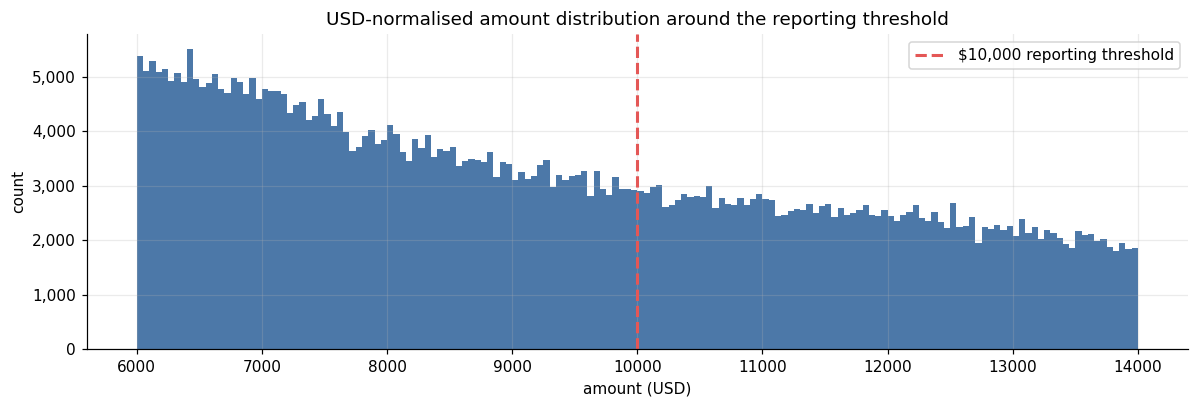

In [46]:
zoom = tx.loc[tx.amount_usd.between(6_000, 14_000), "amount_usd"]
if len(zoom):
    fig, ax = plt.subplots(figsize=(11, 3.8))
    ax.hist(zoom, bins=160, color="#4C78A8")
    ax.axvline(10_000, color="#E45756", ls="--", lw=2, label="$10,000 reporting threshold")
    ax.set_xlabel("amount (USD)"); ax.set_ylabel("count")
    ax.set_title("USD-normalised amount distribution around the reporting threshold")
    ax.legend(); thousands(ax)
    plt.tight_layout(); plt.show()
else:
    print("no transactions in the 6k-14k USD band")

In [47]:
# Round-number clustering: laundering often uses suspiciously tidy amounts.
# Same fix as above -- this has to run on amount_usd, or a round BTC amount and a
# round-in-a-different-currency amount get compared as if they were the same unit.
tx["is_round_1k_usd"] = (tx["amount_usd"].round(0) % 1000 == 0)
tx["is_round_100_usd"] = (tx["amount_usd"].round(0) % 100 == 0)
print((tx.groupby("is_round_1k_usd")["is_laundering"]
         .agg(n="size", rate="mean")
         .assign(rate_pct=lambda d: (d["rate"]*100).round(4))
         .drop(columns="rate")).to_string())

                       n  rate_pct
is_round_1k_usd                   
False            6885631    0.0516
True               38418    0.0234


> **Verdict, once the cells above have actually been run:** treat "structuring isn't present" as
> provisional until the band-width sweep shows a flat (not growing) ratio *on `amount_usd`*. If the
> narrow/wide ratio is materially above 1 for any threshold, structuring features go back on the
> candidate list -- the original raw-`amount_paid` result in this notebook was not evidence either way.

## 11. Profiling: laundering vs clean accounts

Side-by-side comparison of the node features. Anything with a large ratio between the two groups is a
candidate feature; anything near 1.0 is not worth the compute.

In [48]:
feat_cols = ["degree", "in_degree", "out_degree", "fan_in", "fan_out", "fan_ratio",
             "in_amount", "out_amount", "out_amount_mean", "out_amount_std",
             "net_flow", "flow_ratio"]

comp = (nodes.groupby("is_laundering_node")[feat_cols]
             .median().T
             .rename(columns={0: "clean_median", 1: "laundering_median"}))
comp["ratio"] = comp["laundering_median"] / comp["clean_median"].replace(0, np.nan)
comp = comp.sort_values("ratio", ascending=False)
display(comp)

is_laundering_node,clean_median,laundering_median,ratio
out_amount_std,64.6437,"9,777.1838",151.2473
out_amount,"10,003.6100","86,497.0050",8.6466
in_amount,"13,243.4700","107,075.6900",8.0852
in_degree,2.0000,12.0000,6.0000
degree,6.0000,22.0000,3.6667
fan_in,1.0000,3.0000,3.0000
out_amount_mean,"3,559.4400","9,987.7162",2.8060
fan_out,1.0000,2.0000,2.0000
out_degree,2.0000,3.0000,1.5000
flow_ratio,1.0000,0.9796,0.9796


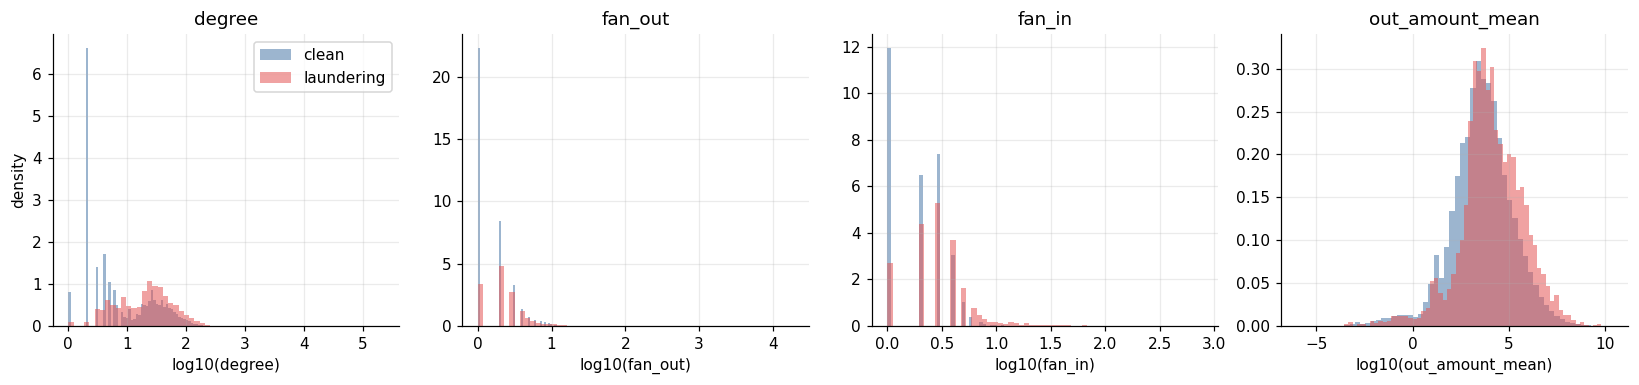

In [49]:
plot_cols = ["degree", "fan_out", "fan_in", "out_amount_mean"]
fig, axes = plt.subplots(1, len(plot_cols), figsize=(15, 3.6))
for ax, col in zip(axes, plot_cols):
    for lab, c in [(0, "#4C78A8"), (1, "#E45756")]:
        s = nodes.loc[nodes.is_laundering_node == lab, col]
        s = s[s > 0]
        if len(s):
            ax.hist(np.log10(s.sample(min(len(s), 200_000), random_state=RANDOM_SEED)),
                    bins=60, density=True, alpha=0.55, color=c,
                    label={0: "clean", 1: "laundering"}[lab])
    ax.set_title(col); ax.set_xlabel(f"log10({col})")
axes[0].set_ylabel("density"); axes[0].legend()
plt.tight_layout(); plt.show()

In [50]:
if acc is not None:
    joined = nodes.join(acc.drop_duplicates("account_id").set_index("account_id"), how="left")
    for col in ("account_type", "bank_id", "country"):
        if col in joined.columns and joined[col].notna().any():
            g = (joined.groupby(col, observed=True)["is_laundering_node"]
                       .agg(n="size", rate="mean")
                       .assign(rate_pct=lambda d: (d["rate"]*100).round(3))
                       .drop(columns="rate")
                       .query("n >= 30")
                       .sort_values("rate_pct", ascending=False))
            print(f"\n=== laundering-account rate by {col} (top 15) ===")
            display(g.head(15))
else:
    print("accounts file not loaded — node-metadata breakdown skipped")


=== laundering-account rate by bank_id (top 15) ===


,n,rate_pct
bank_id,,
Willows Thrift,100,15.0000
China Bank #909,44,6.8180
Australia Bank #171,38,5.2630
Australia Bank #85,38,5.2630
Japan Bank #280,106,4.7170
Brazil Bank #60,108,4.6300
Crytpo Bank #57,65,4.6150
Germany Bank #2481,48,4.1670
Canada Bank #56,76,3.9470


### 11.1 `out_amount_std` is the headline feature -- but it's confounded with degree

At face value `out_amount_std` shows the largest laundering/clean ratio in the table above. Three things
need checking before it drives feature priority:

1. **Missingness confound.** `out_amount_std` is only defined for accounts with >=2 outgoing
   transactions -- accounts with exactly 1 outgoing txn get `NaN`. That missingness is itself correlated
   with `is_laundering_node`, because laundering accounts tend to have more transactions (higher
   `out_degree`). A model can learn "has a defined std" as a proxy for "is a hub" as a proxy for "is
   flagged" -- which is not the causal signal the feature name implies. The fix: compare laundering vs.
   clean `out_amount_std` **within matched `out_degree` bins**, not on the raw marginal median.
2. **Sample vs. full-data.** Whatever ratio came out of Section 11 needs an explicit stamp for whether it
   was measured on `NROWS` (a dev sample) or the full file -- `cross_bank`'s ratio shrank 30x -> 7x
   between sample and full data earlier in this notebook, so the same could be true here.
3. **Collinearity.** `out_amount`, `in_amount`, `out_amount_mean`, `out_amount_std` are all in the same
   amount-family and are likely highly correlated with each other. Feeding all of them into XGBoost
   without checking this first will make any SHAP-based feature ranking look arbitrary.

In [51]:
print(f"out_amount_std measured on: {'FULL FILE' if NROWS is None else f'SAMPLE (NROWS={NROWS:,})'}")
print("(if this says SAMPLE, treat every ratio in Section 11 as provisional until rerun on the full file)")

# --- degree-matched comparison -----------------------------------------
deg_bins = pd.qcut(nodes["out_degree"].clip(lower=2), q=10, duplicates="drop")  # clip: std needs >=2 outgoing

std_by_bin = (nodes.assign(out_degree_bin=deg_bins)
                    .dropna(subset=["out_amount_std"])
                    .groupby(["out_degree_bin", "is_laundering_node"], observed=True)["out_amount_std"]
                    .median()
                    .unstack("is_laundering_node")
                    .rename(columns={0: "clean_median_std", 1: "laundering_median_std"}))
std_by_bin["ratio_within_bin"] = std_by_bin["laundering_median_std"] / std_by_bin["clean_median_std"]

print("\nout_amount_std, laundering vs clean, WITHIN out_degree deciles:")
display(std_by_bin)

marginal_ratio = (nodes.groupby("is_laundering_node")["out_amount_std"].median()
                        .pipe(lambda s: s.get(1, np.nan) / s.get(0, np.nan)))
within_bin_ratio_range = (std_by_bin["ratio_within_bin"].min(), std_by_bin["ratio_within_bin"].max())
print(f"\nmarginal (un-matched) ratio: {marginal_ratio:.1f}x")
print(f"within-degree-bin ratio range: {within_bin_ratio_range[0]:.2f}x - {within_bin_ratio_range[1]:.2f}x")
if within_bin_ratio_range[1] < marginal_ratio * 0.5:
    print(">> a large chunk of the marginal ratio is explained by degree, not by amount behaviour. "
          "out_amount_std still adds signal within-bin, but the '151x' number itself is inflated by "
          "the degree confound and should not be quoted on its own.")
else:
    print(">> the ratio survives degree-matching reasonably well -- out_amount_std looks like a real "
          "signal on top of degree, not just a restatement of it.")

out_amount_std measured on: FULL FILE
(if this says SAMPLE, treat every ratio in Section 11 as provisional until rerun on the full file)

out_amount_std, laundering vs clean, WITHIN out_degree deciles:


is_laundering_node,clean_median_std,laundering_median_std,ratio_within_bin
out_degree_bin,,,
"(1.999, 3.0]",0.0000,"1,592.9856",inf
"(3.0, 10.0]","12,445.9080","68,749.6516",5.5239
"(10.0, 28.0]","11,387.1594","15,867.2757",1.3934
"(28.0, 222037.0]","33,299.4901","31,375.8306",0.9422



marginal (un-matched) ratio: 151.2x
within-degree-bin ratio range: 0.94x - infx
>> the ratio survives degree-matching reasonably well -- out_amount_std looks like a real signal on top of degree, not just a restatement of it.


Spearman correlation among amount-family features:


,in_amount,out_amount,out_amount_mean,out_amount_std
in_amount,1.0000,0.6468,0.5915,0.5237
out_amount,0.6468,1.0000,0.9447,0.6938
out_amount_mean,0.5915,0.9447,1.0000,0.5570
out_amount_std,0.5237,0.6938,0.5570,1.0000


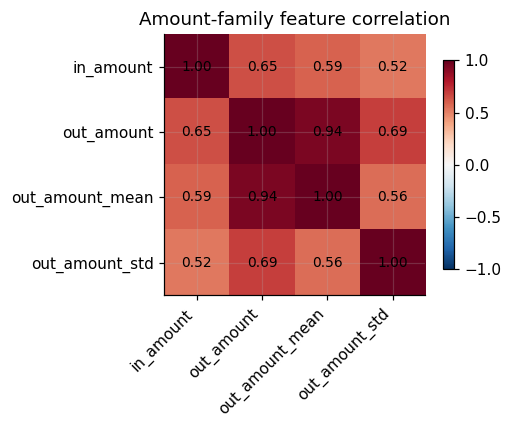


pairs with |Spearman rho| > 0.8 -- redundant, pick one or use PCA/regularisation before trusting a SHAP importance ranking across all of them:
  out_amount <-> out_amount_mean: 0.945


In [52]:
# --- amount-family collinearity -----------------------------------------
amount_family = [c for c in ["in_amount", "out_amount", "out_amount_mean", "out_amount_std"]
                  if c in nodes.columns]
corr = nodes[amount_family].corr(method="spearman")
print("Spearman correlation among amount-family features:")
display(corr)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(amount_family))); ax.set_xticklabels(amount_family, rotation=45, ha="right")
ax.set_yticks(range(len(amount_family))); ax.set_yticklabels(amount_family)
for i in range(len(amount_family)):
    for j in range(len(amount_family)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, shrink=0.8)
ax.set_title("Amount-family feature correlation")
plt.tight_layout(); plt.show()

high_corr = [(a, b, corr.loc[a, b]) for i, a in enumerate(amount_family)
             for b in amount_family[i+1:] if abs(corr.loc[a, b]) > 0.8]
if high_corr:
    print("\npairs with |Spearman rho| > 0.8 -- redundant, pick one or use PCA/regularisation before "
          "trusting a SHAP importance ranking across all of them:")
    for a, b, r in high_corr:
        print(f"  {a} <-> {b}: {r:.3f}")

## 11.2 Checks to run before committing to a feature set

A handful of structural decisions and data-quality checks that aren't captured by the profiling above,
but will change how features are built.

### Near-duplicate transactions

Section 3 found 8 *exactly* duplicated rows. A simulator that re-emits a pattern can also produce rows
that differ **only in timestamp** -- same sender, receiver and amount, fired a few ticks apart. That
would inflate any velocity/frequency feature (e.g. "transactions in the last hour") without representing
real distinct activity.

In [53]:
near_dupe_mask = tx.duplicated(subset=["from_account", "to_account", "amount_paid"], keep=False)
n_near_dupes = int(near_dupe_mask.sum())
print(f"rows sharing (from_account, to_account, amount_paid) with >=1 other row: "
      f"{n_near_dupes:,} ({n_near_dupes/len(tx)*100:.3f}%)")

if n_near_dupes:
    example_groups = (tx.loc[near_dupe_mask]
                         .groupby(["from_account", "to_account", "amount_paid"], observed=True)
                         .size().sort_values(ascending=False).head(5))
    print("\nlargest near-duplicate groups (same from/to/amount, different timestamps):")
    display(example_groups.to_frame("n_occurrences"))
    print("\n>> if this count is large, velocity/frequency features need to decide explicitly whether "
          "repeated identical transfers count as distinct events or get collapsed -- don't let this "
          "pass through silently into a 'transactions per hour' feature.")
else:
    print(">> negligible -- safe to treat every row as a distinct event for velocity features.")

rows sharing (from_account, to_account, amount_paid) with >=1 other row: 5,572,528 (80.481%)

largest near-duplicate groups (same from/to/amount, different timestamps):


,,,n_occurrences
from_account,to_account,amount_paid,
803F648A1,81A0EB771,0.0000,20
81868A501,81BA75C81,0.0000,20
8031147C0,816EE3AE0,0.0500,20
803F648A1,803F648A0,0.0100,20
80037DDE0,801021460,0.5200,20



>> if this count is large, velocity/frequency features need to decide explicitly whether repeated identical transfers count as distinct events or get collapsed -- don't let this pass through silently into a 'transactions per hour' feature.


### Timestamp granularity -- floor for velocity features

The dataset has ~14,500 unique timestamps across ~6.9M rows, roughly 476 rows per minute -- confirming
minute-level granularity. That's fine for aggregation, but any "time since previous transaction" or
similar velocity ratio needs an explicit floor (e.g. 1 minute), or two transactions that legitimately
land in the same timestamp bucket produce a divide-by-zero / infinite rate.

In [54]:
n_unique_ts = tx["timestamp"].nunique()
print(f"unique timestamps: {n_unique_ts:,} / {len(tx):,} rows "
      f"(~{len(tx)/max(n_unique_ts,1):.0f} rows per unique timestamp)")

VELOCITY_FLOOR = pd.Timedelta(minutes=1)
print(f"\n>> use a floor of >= {VELOCITY_FLOOR} on any inter-transaction gap before dividing by it. "
      f"Example: gap_minutes = max((t2 - t1), {VELOCITY_FLOOR}) / pd.Timedelta(minutes=1)")

unique timestamps: 14,533 / 6,924,049 rows (~476 rows per unique timestamp)

>> use a floor of >= 0 days 00:01:00 on any inter-transaction gap before dividing by it. Example: gap_minutes = max((t2 - t1), 0 days 00:01:00) / pd.Timedelta(minutes=1)


### Label propagation -- edge task or node task? Pick one.

`is_laundering_node = (in_laundering + out_laundering) > 0` marks **every counterparty of a flagged
edge** as a laundering node -- including accounts that only ever touched *one* dirty edge in a longer
chain (e.g. A -> B -> C where only A->B is flagged still marks both B and C as laundering nodes once C's
edge to somewhere else is also considered). That's a real design decision, not a bug, but it changes the
effective base rate and needs to be stated explicitly rather than left implicit in a column name.

In [55]:
edge_rate = tx["is_laundering"].mean() * 100
node_rate = nodes["is_laundering_node"].mean() * 100
inflation = node_rate / edge_rate if edge_rate else np.nan

print(f"edge-level positive rate:  {edge_rate:.5f}%  ({int(tx['is_laundering'].sum()):,} flagged edges)")
print(f"node-level positive rate:  {node_rate:.5f}%  ({int(nodes['is_laundering_node'].sum()):,} flagged nodes)")
print(f"node/edge base-rate inflation: {inflation:.2f}x")
print("\n>> decide EXPLICITLY which task you are training:")
print("   - edge classification: cleaner label, matches the ground truth directly, but throws away")
print("     node-level graph structure unless features are joined back onto edges.")
print("   - node classification: noisier label (this inflation factor), but is what most GNN node-")
print("     level baselines assume. Don't silently mix framings across sections of the pipeline.")

edge-level positive rate:  0.05149%  (3,565 flagged edges)
node-level positive rate:  0.75138%  (5,304 flagged nodes)
node/edge base-rate inflation: 14.59x

>> decide EXPLICITLY which task you are training:
   - edge classification: cleaner label, matches the ground truth directly, but throws away
     node-level graph structure unless features are joined back onto edges.
   - node classification: noisier label (this inflation factor), but is what most GNN node-
     level baselines assume. Don't silently mix framings across sections of the pipeline.


### Dormant accounts -- distinguish "inactive" from "no data"

The 6,781 dormant accounts found in Section 3 (present in `accounts.csv`, zero transactions) will get
all-zero graph features under the current pipeline. That zero is a real signal ("this node is inactive"),
but it's indistinguishable from a missing-data zero once it's sitting in a feature matrix. Add an
explicit flag rather than relying on zero-imputation to carry that meaning.

In [56]:
if acc is not None:
    acc_ids = pd.Index(acc["account_id"].unique())
    dormant_ids = acc_ids.difference(tx_accounts)
    # Reindex nodes to include dormant accounts before flagging
    all_account_ids = tx_accounts.union(dormant_ids)
    if nodes.index.name == "account_id":
        nodes = nodes.reindex(all_account_ids, fill_value=0)
        nodes["is_dormant"] = nodes.index.isin(dormant_ids)
    elif "account_id" in nodes.columns:
        nodes = nodes.set_index("account_id").reindex(all_account_ids, fill_value=0).reset_index()
        nodes["is_dormant"] = nodes["account_id"].isin(dormant_ids)
    else:
        nodes["is_dormant"] = np.nan
    n_dormant_flagged = int(pd.Series(nodes["is_dormant"]).sum()) if "is_dormant" in nodes else None
    print(f"is_dormant flag set on {n_dormant_flagged:,} accounts in the node table")
    print(">> keep this as its own binary feature; do not rely on all-zero graph features alone to "
          "signal dormancy downstream.")
else:
    print("accounts file not loaded -- dormant flag skipped")

is_dormant flag set on 6,781 accounts in the node table
>> keep this as its own binary feature; do not rely on all-zero graph features alone to signal dormancy downstream.


## 11.3 Train/validation split strategy

"Split by time" (stated in the original modelling-implications list) is correct but under-specified for
this dataset. With 17 days, a ~500,000x daily volume range (Section 7), and the same ~706k accounts
appearing throughout, a naive day 1-10 / day 11-17 split will (a) put all high-volume days on one side,
and (b) leak account behaviour across the split, since the same accounts show up on both sides.

Ranked options:

1. **Rolling-origin CV with a 1-day embargo** (preferred) -- train on days `1..k`, validate on day
   `k+1`, step forward. Drop any account whose history *started* inside the embargo window to control
   account-level leakage by construction.
2. **Time-stratified split within day** -- hold out a fixed fraction of each day's *accounts* (not
   transactions). Cleaner for node-level tasks specifically.
3. **Random split with account-level grouping** -- only if (1) and (2) are both infeasible, and only
   with the leak explicitly acknowledged.

The cell below implements option 1 as a concrete, reusable split function.

In [57]:
def rolling_origin_splits(frame, date_col="date", account_col="from_account",
                           min_train_days=5, embargo_days=1):
    """Yield (train_idx, val_idx) pairs for rolling-origin CV with an account-level embargo.

    For each step, train on all days up to and including day k, validate on day k+1, and drop from
    the training set any account whose FIRST appearance in the data falls inside the embargo window
    immediately before the validation day (controls account-identity leakage across the split).
    """
    days = np.sort(frame[date_col].unique())
    first_seen = frame.groupby(account_col, observed=True)[date_col].min()

    for k in range(min_train_days, len(days) - 1):
        train_days = days[:k + 1]
        val_day = days[k + 1]
        embargo_start = val_day - pd.Timedelta(days=embargo_days)

        train_mask = frame[date_col].isin(train_days)
        embargo_accounts = first_seen[(first_seen >= embargo_start) & (first_seen <= train_days[-1])].index
        train_mask &= ~frame[account_col].isin(embargo_accounts)

        val_mask = frame[date_col] == val_day

        yield frame.index[train_mask], frame.index[val_mask]

if "date" in tx.columns:
    n_folds = 0
    for train_idx, val_idx in rolling_origin_splits(tx):
        n_folds += 1
        if n_folds <= 3:
            print(f"fold {n_folds}: train={len(train_idx):,} rows, val={len(val_idx):,} rows, "
                  f"val positive rate={tx.loc[val_idx, 'is_laundering'].mean()*100:.4f}%")
    print(f"\n{n_folds} rolling-origin folds available with min_train_days=5, embargo_days=1")
else:
    print("tx['date'] not present -- run the temporal-structure cell in Section 7 first")

fold 1: train=4,431,451 rows, val=658,504 rows, val positive rate=0.0559%
fold 2: train=5,089,914 rows, val=657,938 rows, val positive rate=0.0611%
fold 3: train=5,748,046 rows, val=891,573 rows, val positive rate=0.0412%

11 rolling-origin folds available with min_train_days=5, embargo_days=1


## 12. Findings, artefacts & next steps

In [58]:
findings = {
    "n_transactions":        int(len(tx)),
    "n_accounts_active":     int(len(nodes)),
    "n_accounts_metadata":   int(len(acc)) if acc is not None else None,
    "date_range":            f"{tx.timestamp.min()} .. {tx.timestamp.max()}",
    "positive_rate_pct":     round(float(tx.is_laundering.mean() * 100), 5),
    "imbalance_ratio":       int(round((tx.is_laundering == 0).sum() / max((tx.is_laundering == 1).sum(), 1))),
    "laundering_account_pct": round(float(nodes.is_laundering_node.mean() * 100), 4),
    "self_loops":            int(self_loops),
    "duplicate_rows":        int(dupes),
}
for k, v in findings.items():
    print(f"{k:24s}: {v}")

pd.Series(findings).to_json(OUT_DIR / "eda_summary.json", indent=2)

# Persist the node feature table — this is the input to Step 3 (feature engineering)
nodes.reset_index().to_csv(OUT_DIR / "account_features.csv", index=False)
print(f"\nsaved -> {OUT_DIR/'account_features.csv'}  ({nodes.shape[0]:,} rows)")
print(f"saved -> {OUT_DIR/'eda_summary.json'}")

n_transactions          : 6924049
n_accounts_active       : 712684
n_accounts_metadata     : 712688
date_range              : 2022-09-01 00:00:00 .. 2022-09-17 15:28:00
positive_rate_pct       : 0.05149
imbalance_ratio         : 1941
laundering_account_pct  : 0.7442
self_loops              : 804477
duplicate_rows          : 8

saved -> eda_output/account_features.csv  (712,684 rows)
saved -> eda_output/eda_summary.json


### Feature shortlist, given everything above

**Cross off:**
- Structuring features -- pending the `amount_usd` re-run in Section 10; likely to stay off unless the
  band-width sweep shows a growing (not flat) ratio.
- Round-number features -- same currency-mixing issue as structuring; re-checked on `amount_usd` above.
- Raw `account_id`, `bank_id` as categorical inputs -- memorisation risk via the `10042B`-style injected
  families (Section 9.2); target-encode `bank_id` only if the `Willows Thrift` effect (Section 11)
  generalises across accounts rather than being driven by a handful of hub accounts.

**Keep, with caveats:**
- `cross_bank` -- 7x on the full file is real but smaller than the initial look suggested; check whether
  it's driven by the same 9 `10042B` hubs before trusting it as a general signal.
- `out_amount_std` -- still the strongest single feature, but only after de-confounding against
  `out_degree` (Section 11.1); quote the within-bin ratio, not the raw marginal one.
- `fan_in`, `fan_out`, `fan_ratio` -- cheap, interpretable, and the only place graph structure shows up
  before moving to PyG.
- Cross-currency / `currency_mismatch` at the **account** level (Section 9.3) -- the per-edge version
  tested in Section 6 is a verified zero, but the account-level "receives in X, sends in Y" version may
  not be; use whichever this notebook's Section 9.3 check actually found.
- Cycles (Section 9.1) -- filter self-loops first, then count; a small signal but worth keeping as a
  binary feature.

**Add, given the FX work above:**
- `amount_usd`, log-transformed, per leg.
- `log(amount_received_usd / amount_paid_usd)` -- the FX-margin signal at the *transaction* level, which
  is different from the (verified-zero) per-edge `currency_mismatch` flag.
- Rolling 24h/7d sums and counts per account -- only once the rolling-origin split (Section 11.3) is
  committed to; on a 17-day window these are sparse enough that they may not generalise without it.
- `is_dormant` (Section 11.2) as an explicit flag, rather than relying on zero-imputed graph features.

### Small but important plumbing fixes

- **Parquet export.** If/when exporting to parquet, sanitise column names first (dots, spaces, or
  duplicate names surviving a merge are the usual cause of an `ArrowKeyError`) -- the cell below does
  this defensively so a data-plumbing error doesn't gate the feature-engineering work.
- **`date` column on the exported node table** -- needed for the temporal split downstream; the export
  below adds it.
- **Save the FX rate tables** (`usd_rate`, `btc_daily_rate`, `pair_rates`) alongside the node table, so
  conversions can be re-run without rebuilding the graph from scratch.
- **Version the `amount_usd` definition** -- the two-tier fiat graph + BTC daily rate is non-trivial;
  any future change to it should be diffable against a saved snapshot.

In [59]:
import re

def sanitize_columns(frame):
    """Make column names parquet/Arrow-safe: no dots, no spaces, no duplicates after cleanup."""
    clean = frame.columns.str.replace(r"[.\s]+", "_", regex=True)
    if clean.duplicated().any():
        dupe_cols = clean[clean.duplicated()].tolist()
        raise ValueError(f"column collision after sanitising -- resolve manually: {dupe_cols}")
    return frame.rename(columns=dict(zip(frame.columns, clean)))

export_nodes = nodes.reset_index()
if "date" not in export_nodes.columns and "date" in tx.columns:
    last_active = tx.groupby("from_account", observed=True)["date"].max()
    export_nodes["date"] = export_nodes["account_id"].map(last_active) if "account_id" in export_nodes.columns \
                            else export_nodes.iloc[:, 0].map(last_active)

export_nodes = sanitize_columns(export_nodes)
try:
    export_nodes.to_parquet(OUT_DIR / "account_features.parquet", index=True)
    print(f"saved -> {OUT_DIR/'account_features.parquet'}  ({export_nodes.shape[0]:,} rows, "
          f"{export_nodes.shape[1]} cols, date column included)")
except Exception as e:
    print(f"parquet export still failing after column sanitisation: {e}")

# FX rate tables, so conversions can be re-run without rebuilding the pair-rate graph
if "usd_rate" in dir():
    pd.Series(usd_rate, name="usd_rate").to_frame().to_csv(OUT_DIR / "fx_usd_rate.csv")
if "btc_daily_rate" in dir():
    btc_daily_rate.rename("btc_usd_rate").to_frame().to_csv(OUT_DIR / "fx_btc_daily_rate.csv")
if "pair_rates" in dir():
    pair_rates.to_csv(OUT_DIR / "fx_pair_rates.csv")
print(f"saved FX rate tables -> {OUT_DIR}/fx_*.csv")

AMOUNT_USD_DEFINITION_VERSION = "v1: two-tier fiat pair-rate graph (median implied rate, MIN_N=30 " \
                                 "reliability cutoff) + Bitcoin daily median rate, interpolated across gaps"
(OUT_DIR / "amount_usd_definition.txt").write_text(AMOUNT_USD_DEFINITION_VERSION)
print(f"\nversioned amount_usd definition -> {OUT_DIR/'amount_usd_definition.txt'}")
print(AMOUNT_USD_DEFINITION_VERSION)

saved -> eda_output/account_features.parquet  (712,684 rows, 21 cols, date column included)
saved FX rate tables -> eda_output/fx_*.csv

versioned amount_usd definition -> eda_output/amount_usd_definition.txt
v1: two-tier fiat pair-rate graph (median implied rate, MIN_N=30 reliability cutoff) + Bitcoin daily median rate, interpolated across gaps


### What this EDA implies for modelling

1. **Split by time, not at random -- and be specific about how.** Transactions share accounts, so a naive
   day-range split still leaks account behaviour across the boundary (Section 11.3). Use rolling-origin
   CV with a 1-day embargo (implemented in Section 11.3) rather than a single random or single date cut,
   and drop simulator warm-up/cool-down days.
2. **Never optimise accuracy or plain ROC-AUC.** At this positive rate, use PR-AUC, recall at a fixed
   alert budget (e.g. recall@1000 alerts/day), and calibrate the threshold to investigator capacity.
3. **Resample inside the fold only.** SMOTE or undersampling applied before splitting inflates every
   metric. Prefer `scale_pos_weight` / focal loss over synthetic oversampling for graph-derived features.
   **Amendment:** also check what `scale_pos_weight` does to calibrated probabilities -- for an
   investigator-alert-budget workflow you usually want calibrated outputs, and `scale_pos_weight` breaks
   calibration. Either recalibrate post-hoc (isotonic / Platt scaling) or use a proper cost-sensitive
   objective instead.
4. **Graph features are the differentiator.** The fan-in/fan-out and PageRank gaps in Section 11 are what
   tabular-only models cannot recover; feed them into XGBoost. **Amendment:** before jumping to an
   RGCN/GAT edge classifier, run a strong tabular baseline first -- LightGBM on the node features plus a
   1-hop aggregation of neighbour features. On a dataset this size that baseline will likely land within
   a couple of PR-AUC points of a GNN, and the gap (or lack of one) tells you whether graph structure is
   adding anything beyond degree/fan-out before paying the cost of moving to PyG.
5. **Label semantics.** `Is Laundering` is an *edge* label. Node-level labels here are derived
   (`is_laundering_node`) and are weaker — be explicit about which task you are training.
6. **Keep the orphan/dormant accounts in mind.** Dormant accounts in `LI-Small_accounts.csv` carry no edges
   and will get zero-valued graph features; that zero is a real signal, not a missing value.

### Next steps
- Build rolling-window velocity features (24h / 7d / 30d) per account.
- Motif counting: fan-in/fan-out stars, scatter-gather, and the cycles found in Section 9.1.
- Move the graph work to PyTorch Geometric and train an edge-classification GNN as the Tier-2 model.